# Generate the deterministic simulation programs

This notebook regenerates the twelve ODE programs used in the paper benchmark. Each program retains its original rates or seeded rate draws, initial conditions, RK45 integration, rounding before scaling, and target totals. The sampling coordinates are 0, 4, 9 and 15, labelled t1–t4 in the benchmark.

The generated expected-count profiles are checked exactly against the registered reference. Integer clean counts are obtained by rounding these profiles once; the separate noise-validation workflow keeps the complete t1 count vector fixed and perturbs only t2–t4. This notebook does not apply the older demonstration's noise model.

Run all cells from the benchmark directory. Outputs go to `results/reproduced_reference/`; the registered files in `reference/` are read-only inputs. Parameter values, expressions, initial conditions and ODE equations are exported alongside the regenerated profiles.

Recorded environment: **chronoclone**, `/path/to/ChronoClone/.runtime/chronoclone`; kernel **chronoclone-paper**. The next cell prints exact versions and the command used for this execution.

This execution uses the existing **chronoclone** micromamba environment at `/path/to/ChronoClone/.runtime/chronoclone`, kernel **chronoclone-paper**. Exact MacBook command:
```bash
JUPYTER_PATH=/path/to/ChronoClone/.runtime/jupyter /path/to/ChronoClone/.runtime/chronoclone/bin/python /path/to/ChronoClone/ChronoClone_paper/benchmarks/run_notebook.py /path/to/ChronoClone/ChronoClone_paper/benchmarks/ode_noise/notebooks/0001_simulation.ipynb --kernel chronoclone-paper
```

In [1]:
from pathlib import Path
import hashlib, inspect, json, sys
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, RK45
from IPython.display import display

parents=[Path.cwd(),*Path.cwd().parents]
BENCHMARK=next(candidate for parent in parents
               for candidate in (parent,parent/'in_silico',parent/'benchmarks/ode_noise')
               if (candidate/'reference/deterministic_profiles.csv').is_file()
               and (candidate/'reference/program_manifest.csv').is_file())
REFERENCE=BENCHMARK/'reference'
OUT=BENCHMARK/'results/reproduced_reference'
FIGURES=OUT/'figures'
FIGURES.mkdir(parents=True,exist_ok=True)
def sha(path):return hashlib.sha256(path.read_bytes()).hexdigest()
expected_profile_sha='e4275d94c1513026dc684bcca44703135bba4af4694ec55cd714d3c0fa21bf6f'
expected_manifest_sha='ba890ce14f052113d203904aa158cab79c36794c4edaf638ee0afd5b85063d11'
assert sha(REFERENCE/'deterministic_profiles.csv')==expected_profile_sha
assert sha(REFERENCE/'program_manifest.csv')==expected_manifest_sha
canonical_profiles=np.loadtxt(REFERENCE/'deterministic_profiles.csv',delimiter=',').reshape(12,4,13)
canonical_manifest=pd.read_csv(REFERENCE/'program_manifest.csv')
STATES=['HSC','HSPC','MEP','CMP','Mk_prog','MEMP','GMP','GMDP','Mast_prog','Baso_prog','Neu_prog','DC_prog','Mono_prog']
TIME_LABELS=['t1','t2','t3','t4']
profiles=[]
program_records=[]
parameter_records=[]
equivalence_records=[]
figure_records=[]
rk45_defaults={name:inspect.signature(RK45).parameters[name].default for name in ['rtol','atol']}
environment={'name':'chronoclone','path':sys.prefix,'kernel':'chronoclone-paper',
             'python':sys.version.split()[0],
             'versions':{name:version(name) for name in ['numpy','pandas','scipy','matplotlib','nbformat','nbconvert']},
             'RK45_defaults':rk45_defaults}
display(environment)
print('Execution command, from the benchmark directory:')
print('JUPYTER_PATH=/path/to/ChronoClone/.runtime/jupyter /path/to/ChronoClone/.runtime/chronoclone/bin/python -m nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone-paper --ExecutePreprocessor.timeout=600 notebooks/0001_simulation.ipynb')


{'name': 'chronoclone',
 'path': '/path/to/ChronoClone/.runtime/chronoclone',
 'kernel': 'chronoclone-paper',
 'python': '3.11.15',
 'versions': {'numpy': '2.4.6',
  'pandas': '2.3.3',
  'scipy': '1.17.1',
  'matplotlib': '3.11.0',
  'nbformat': '5.10.4',
  'nbconvert': '7.17.1'},
 'RK45_defaults': {'rtol': 0.001, 'atol': 1e-06}}

Execution command, from the benchmark directory:
JUPYTER_PATH=/path/to/ChronoClone/.runtime/jupyter /path/to/ChronoClone/.runtime/chronoclone/bin/python -m nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone-paper --ExecutePreprocessor.timeout=600 notebooks/0001_simulation.ipynb


## Program 1

The complete deterministic calculation and its profile plot are in one cell. The result is checked against the corresponding registered program before export.

,HSC,HSPC,MEP,CMP,Mk_prog,MEMP,GMP,GMDP,Mast_prog,Baso_prog,Neu_prog,DC_prog,Mono_prog
t1,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
t2,66.666667,33.333333,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
t3,31.578947,47.368421,39.473684,31.578947,15.789474,15.789474,7.894737,7.894737,31.578947,39.473684,15.789474,7.894737,7.894737
t4,6.395349,16.860465,33.720930,20.930233,15.697674,15.697674,5.232558,11.046512,88.953488,115.116279,36.046512,19.767442,14.534884


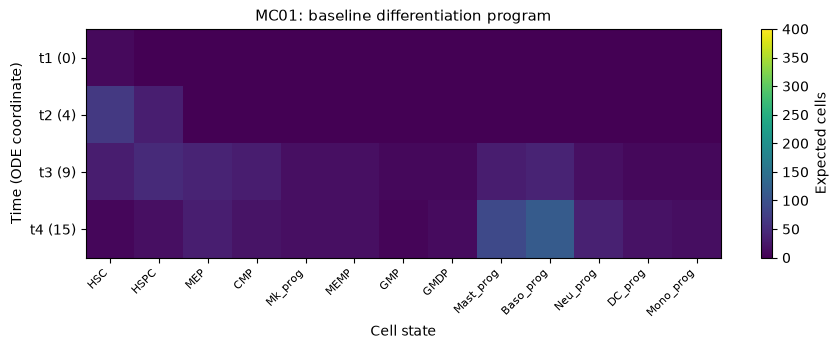

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Define Parameters and ODE System
# ---------------------------------------------------------

def hematopoietic_model(t, y):
    dydt = np.zeros_like(y)
    
    # Parameters
    p_hsc, d_hsc, m_hsc = 0.3, 0.13, 0.01
    p_hspc, d_hspc, m_hspc = 0.35, 0.14, 0.01
    p_mep, d_mep, m_mep = 0.4, 0.1, 0.01
    p_cmp, d_cmp, m_cmp = 0.31, 0.09, 0.01
    p_mk, m_mk = 0.22, 0.01
    p_memp, d_memp, m_memp = 0.7, 0.6, 0.05
    p_gmp, d_gmp, m_gmp = 0.9, 0.8, 0.08
    p_gmdp, d_gmdp, m_gmdp = 0.6, 0.3, 0.07
    p_mast, m_mast = 0.51, 0.09
    p_baso, m_baso = 0.5, 0.03
    p_neu, m_neu = 0.4, 0.033
    p_dc, m_dc = 0.44, 0.1
    p_mono, m_mono = 0.45, 0.2

    x = y 

    # ODE Equations
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    return dydt

# ---------------------------------------------------------
# 2. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
# FIX: Use linspace instead of arange to avoid floating point issues
t_plot = np.linspace(0, 20, 2001)  # 2001 points gives 0.01 spacing
I0 = np.zeros(13)
I0[0] = 1.0

# ---------------------------------------------------------
# 3. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)

# Target sums for each timepoint: [10, 100, 300, 400]
target_sums = np.array([10, 100, 300, 400]).reshape(-1, 1)

# Normalize and Scale: (Model / Current_Sum) * Target_Sum
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------


# Record this program, verify its exact expected counts, and draw one profile heatmap.
program_number=1
program_id=f'MC{program_number:02d}'
program_clone_count=15
program_seed=None
program_rates={'p_hsc': 0.3, 'd_hsc': 0.13, 'm_hsc': 0.01, 'p_hspc': 0.35, 'd_hspc': 0.14, 'm_hspc': 0.01, 'p_mep': 0.4, 'd_mep': 0.1, 'm_mep': 0.01, 'p_cmp': 0.31, 'd_cmp': 0.09, 'm_cmp': 0.01, 'p_mk': 0.22, 'm_mk': 0.01, 'p_memp': 0.7, 'd_memp': 0.6, 'm_memp': 0.05, 'p_gmp': 0.9, 'd_gmp': 0.8, 'm_gmp': 0.08, 'p_gmdp': 0.6, 'd_gmdp': 0.3, 'm_gmdp': 0.07, 'p_mast': 0.51, 'm_mast': 0.09, 'p_baso': 0.5, 'm_baso': 0.03, 'p_neu': 0.4, 'm_neu': 0.033, 'p_dc': 0.44, 'm_dc': 0.1, 'p_mono': 0.45, 'm_mono': 0.2}
rate_expressions={'p_hsc': '0.3', 'd_hsc': '0.13', 'm_hsc': '0.01', 'p_hspc': '0.35', 'd_hspc': '0.14', 'm_hspc': '0.01', 'p_mep': '0.4', 'd_mep': '0.1', 'm_mep': '0.01', 'p_cmp': '0.31', 'd_cmp': '0.09', 'm_cmp': '0.01', 'p_mk': '0.22', 'm_mk': '0.01', 'p_memp': '0.7', 'd_memp': '0.6', 'm_memp': '0.05', 'p_gmp': '0.9', 'd_gmp': '0.8', 'm_gmp': '0.08', 'p_gmdp': '0.6', 'd_gmdp': '0.3', 'm_gmdp': '0.07', 'p_mast': '0.51', 'm_mast': '0.09', 'p_baso': '0.5', 'm_baso': '0.03', 'p_neu': '0.4', 'm_neu': '0.033', 'p_dc': '0.44', 'm_dc': '0.1', 'p_mono': '0.45', 'm_mono': '0.2'}
ode_equations='def hematopoietic_model(t, y):\n    dydt = np.zeros_like(y)\n    \n    # Parameters\n    p_hsc, d_hsc, m_hsc = 0.3, 0.13, 0.01\n    p_hspc, d_hspc, m_hspc = 0.35, 0.14, 0.01\n    p_mep, d_mep, m_mep = 0.4, 0.1, 0.01\n    p_cmp, d_cmp, m_cmp = 0.31, 0.09, 0.01\n    p_mk, m_mk = 0.22, 0.01\n    p_memp, d_memp, m_memp = 0.7, 0.6, 0.05\n    p_gmp, d_gmp, m_gmp = 0.9, 0.8, 0.08\n    p_gmdp, d_gmdp, m_gmdp = 0.6, 0.3, 0.07\n    p_mast, m_mast = 0.51, 0.09\n    p_baso, m_baso = 0.5, 0.03\n    p_neu, m_neu = 0.4, 0.033\n    p_dc, m_dc = 0.44, 0.1\n    p_mono, m_mono = 0.45, 0.2\n\n    x = y \n\n    # ODE Equations\n    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] \n    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]\n    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]\n    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]\n    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]\n    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]\n    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]\n    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]\n    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]\n    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]\n    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]\n    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]\n    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]\n\n    return dydt'
source_record={'program': 'MC01', 'historical_notebook': 'simulation_generate.ipynb', 'historical_notebook_sha256': 'a35588c48c547954c48c14d5def17da4b3ed1238a281cf78d20473e1c48a2cea', 'historical_cell_zero_based': 2, 'deterministic_prefix_sha256': '1ca9682370e3ea304f99abf0b4be9adcc9980e27acba894550ec1df28fed4bfd', 'boundary': 'before # Calculate deviation', 'n_clones': 15, 'parameter_seed': None}
assert sol_sample.success and sol_plot.success
profile=np.asarray(model_deterministic,dtype=np.float64).copy()
assert profile.shape==(4,13) and np.isfinite(profile).all() and (profile>=0).all()
assert np.array_equal(time_points,np.array([0,4,9,15]))
assert np.array_equal(profile,canonical_profiles[program_number-1]),program_id
assert program_clone_count==int(canonical_manifest.iloc[program_number-1]['n_clones'])
profiles.append(profile)
description=str(canonical_manifest.iloc[program_number-1]['description'])
program_record=dict(source_record,description=description,initial_conditions=I0.tolist(),
                    sampling_coordinates=time_points.tolist(),target_sums=target_sums.ravel().tolist(),
                    solver='RK45',solver_defaults=rk45_defaults,rate_values=program_rates,
                    rate_expressions=rate_expressions,ode_equations=ode_equations,
                    transformation='round sampled ODE values to nearest even, then rescale each timepoint to its target total')
program_records.append(program_record)
parameter_records.extend({'program':program_id,'parameter':name,'value':float(value),
                          'expression':rate_expressions[name],'parameter_seed':program_seed}
                         for name,value in program_rates.items())
equivalence_records.append({'program':program_id,'n_clones':program_clone_count,
                            'exact_profile_match':True,'maximum_absolute_difference':float(np.max(np.abs(profile-canonical_profiles[program_number-1])))})
display(pd.DataFrame(profile,index=TIME_LABELS,columns=STATES))

with mpl.rc_context({'svg.fonttype':'none','pdf.fonttype':42,'font.family':'DejaVu Sans'}):
    fig,ax=plt.subplots(figsize=(9,3.6))
    image=ax.imshow(profile,aspect='auto',cmap='viridis',vmin=0,
                    vmax=float(canonical_profiles.max()),interpolation='nearest')
    ax.set_xticks(np.arange(len(STATES)))
    ax.set_xticklabels(STATES,rotation=45,ha='right',fontsize=8)
    ax.set_yticks(np.arange(len(TIME_LABELS)))
    ax.set_yticklabels([f'{label} ({coordinate})' for label,coordinate in zip(TIME_LABELS,time_points)])
    ax.set_xlabel('Cell state')
    ax.set_ylabel('Time (ODE coordinate)')
    ax.set_title(f'{program_id}: {description}',fontsize=11)
    fig.colorbar(image,ax=ax,label='Expected cells')
    fig.tight_layout()
    stem=FIGURES/f'{program_id.lower()}_deterministic_profile'
    fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'),dpi=180,bbox_inches='tight')
    display(fig)
plt.close(fig)
figure_records.append({'program':program_id,'svg':str(stem.with_suffix('.svg').relative_to(BENCHMARK)),
                       'svg_sha256':sha(stem.with_suffix('.svg')),
                       'png':str(stem.with_suffix('.png').relative_to(BENCHMARK)),
                       'png_sha256':sha(stem.with_suffix('.png'))})


## Program 2

The complete deterministic calculation and its profile plot are in one cell. The result is checked against the corresponding registered program before export.

,HSC,HSPC,MEP,CMP,Mk_prog,MEMP,GMP,GMDP,Mast_prog,Baso_prog,Neu_prog,DC_prog,Mono_prog
t1,6.666667,3.333333,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
t2,30.000000,40.000000,10.000000,10.000000,0.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
t3,13.793103,41.379310,44.827586,20.689655,20.689655,65.517241,6.896552,3.448276,31.034483,27.586207,6.896552,13.793103,3.448276
t4,1.518438,9.110629,22.342733,6.073753,18.655098,107.809111,4.121475,2.169197,106.507592,91.323210,5.639913,21.691974,3.036876


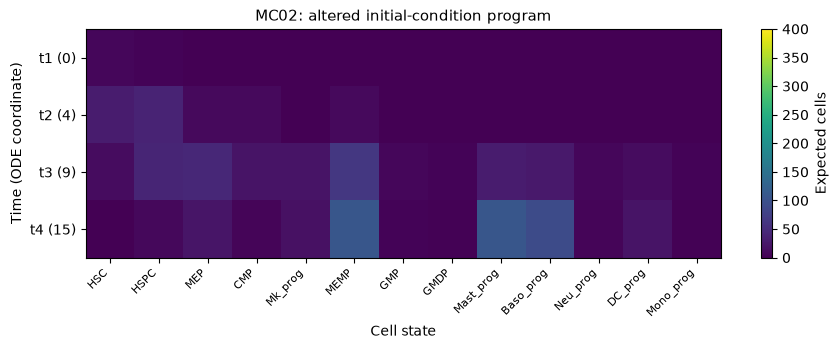

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Define Parameters and ODE System - META2
# ---------------------------------------------------------

def hematopoietic_model_meta2(t, y):
    dydt = np.zeros_like(y)
    
    # META2 Parameters
    p_hsc, d_hsc, m_hsc = 0.2, 0.1, 0.02
    p_hspc, d_hspc, m_hspc = 0.3, 0.1, 0.011
    p_mep, d_mep, m_mep = 0.41, 0.11, 0.012
    p_cmp, d_cmp, m_cmp = 0.2, 0.09, 0.02
    p_mk, m_mk = 0.29, 0.02
    p_memp, d_memp, m_memp = 0.6, 0.1, 0.015
    p_gmp, d_gmp, m_gmp = 0.5, 0.3, 0.018
    p_gmdp, d_gmdp, m_gmdp = 0.4, 0.3, 0.071
    p_mast, m_mast = 0.6, 0.08
    p_baso, m_baso = 0.51, 0.02
    p_neu, m_neu = 0.3, 0.133
    p_dc, m_dc = 0.6, 0.11
    p_mono, m_mono = 0.145, 0.012

    x = y 

    # ODE Equations
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    return dydt

# ---------------------------------------------------------
# 2. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
t_plot = np.linspace(0, 20, 2001)

# META2 Initial Conditions: HSC=2, HSPC=1, others=0
I0 = np.zeros(13)
I0[0] = 2.0  # HSC
I0[1] = 1.0  # HSPC

# ---------------------------------------------------------
# 3. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model_meta2, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model_meta2, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)

# Target sums for each timepoint: [10, 100, 300, 400]
target_sums = np.array([10, 100, 300, 400]).reshape(-1, 1)

# Normalize and Scale: (Model / Current_Sum) * Target_Sum
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------


# Record this program, verify its exact expected counts, and draw one profile heatmap.
program_number=2
program_id=f'MC{program_number:02d}'
program_clone_count=30
program_seed=None
program_rates={'p_hsc': 0.2, 'd_hsc': 0.1, 'm_hsc': 0.02, 'p_hspc': 0.3, 'd_hspc': 0.1, 'm_hspc': 0.011, 'p_mep': 0.41, 'd_mep': 0.11, 'm_mep': 0.012, 'p_cmp': 0.2, 'd_cmp': 0.09, 'm_cmp': 0.02, 'p_mk': 0.29, 'm_mk': 0.02, 'p_memp': 0.6, 'd_memp': 0.1, 'm_memp': 0.015, 'p_gmp': 0.5, 'd_gmp': 0.3, 'm_gmp': 0.018, 'p_gmdp': 0.4, 'd_gmdp': 0.3, 'm_gmdp': 0.071, 'p_mast': 0.6, 'm_mast': 0.08, 'p_baso': 0.51, 'm_baso': 0.02, 'p_neu': 0.3, 'm_neu': 0.133, 'p_dc': 0.6, 'm_dc': 0.11, 'p_mono': 0.145, 'm_mono': 0.012}
rate_expressions={'p_hsc': '0.2', 'd_hsc': '0.1', 'm_hsc': '0.02', 'p_hspc': '0.3', 'd_hspc': '0.1', 'm_hspc': '0.011', 'p_mep': '0.41', 'd_mep': '0.11', 'm_mep': '0.012', 'p_cmp': '0.2', 'd_cmp': '0.09', 'm_cmp': '0.02', 'p_mk': '0.29', 'm_mk': '0.02', 'p_memp': '0.6', 'd_memp': '0.1', 'm_memp': '0.015', 'p_gmp': '0.5', 'd_gmp': '0.3', 'm_gmp': '0.018', 'p_gmdp': '0.4', 'd_gmdp': '0.3', 'm_gmdp': '0.071', 'p_mast': '0.6', 'm_mast': '0.08', 'p_baso': '0.51', 'm_baso': '0.02', 'p_neu': '0.3', 'm_neu': '0.133', 'p_dc': '0.6', 'm_dc': '0.11', 'p_mono': '0.145', 'm_mono': '0.012'}
ode_equations='def hematopoietic_model_meta2(t, y):\n    dydt = np.zeros_like(y)\n    \n    # META2 Parameters\n    p_hsc, d_hsc, m_hsc = 0.2, 0.1, 0.02\n    p_hspc, d_hspc, m_hspc = 0.3, 0.1, 0.011\n    p_mep, d_mep, m_mep = 0.41, 0.11, 0.012\n    p_cmp, d_cmp, m_cmp = 0.2, 0.09, 0.02\n    p_mk, m_mk = 0.29, 0.02\n    p_memp, d_memp, m_memp = 0.6, 0.1, 0.015\n    p_gmp, d_gmp, m_gmp = 0.5, 0.3, 0.018\n    p_gmdp, d_gmdp, m_gmdp = 0.4, 0.3, 0.071\n    p_mast, m_mast = 0.6, 0.08\n    p_baso, m_baso = 0.51, 0.02\n    p_neu, m_neu = 0.3, 0.133\n    p_dc, m_dc = 0.6, 0.11\n    p_mono, m_mono = 0.145, 0.012\n\n    x = y \n\n    # ODE Equations\n    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] \n    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]\n    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]\n    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]\n    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]\n    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]\n    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]\n    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]\n    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]\n    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]\n    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]\n    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]\n    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]\n\n    return dydt'
source_record={'program': 'MC02', 'historical_notebook': 'simulation_generate.ipynb', 'historical_notebook_sha256': 'a35588c48c547954c48c14d5def17da4b3ed1238a281cf78d20473e1c48a2cea', 'historical_cell_zero_based': 4, 'deterministic_prefix_sha256': '596f566ae2fa29161dcbbdef529da59a613c14ff8448d78e55334a174acaabcf', 'boundary': 'before # Calculate deviation', 'n_clones': 30, 'parameter_seed': None}
assert sol_sample.success and sol_plot.success
profile=np.asarray(model_deterministic,dtype=np.float64).copy()
assert profile.shape==(4,13) and np.isfinite(profile).all() and (profile>=0).all()
assert np.array_equal(time_points,np.array([0,4,9,15]))
assert np.array_equal(profile,canonical_profiles[program_number-1]),program_id
assert program_clone_count==int(canonical_manifest.iloc[program_number-1]['n_clones'])
profiles.append(profile)
description=str(canonical_manifest.iloc[program_number-1]['description'])
program_record=dict(source_record,description=description,initial_conditions=I0.tolist(),
                    sampling_coordinates=time_points.tolist(),target_sums=target_sums.ravel().tolist(),
                    solver='RK45',solver_defaults=rk45_defaults,rate_values=program_rates,
                    rate_expressions=rate_expressions,ode_equations=ode_equations,
                    transformation='round sampled ODE values to nearest even, then rescale each timepoint to its target total')
program_records.append(program_record)
parameter_records.extend({'program':program_id,'parameter':name,'value':float(value),
                          'expression':rate_expressions[name],'parameter_seed':program_seed}
                         for name,value in program_rates.items())
equivalence_records.append({'program':program_id,'n_clones':program_clone_count,
                            'exact_profile_match':True,'maximum_absolute_difference':float(np.max(np.abs(profile-canonical_profiles[program_number-1])))})
display(pd.DataFrame(profile,index=TIME_LABELS,columns=STATES))

with mpl.rc_context({'svg.fonttype':'none','pdf.fonttype':42,'font.family':'DejaVu Sans'}):
    fig,ax=plt.subplots(figsize=(9,3.6))
    image=ax.imshow(profile,aspect='auto',cmap='viridis',vmin=0,
                    vmax=float(canonical_profiles.max()),interpolation='nearest')
    ax.set_xticks(np.arange(len(STATES)))
    ax.set_xticklabels(STATES,rotation=45,ha='right',fontsize=8)
    ax.set_yticks(np.arange(len(TIME_LABELS)))
    ax.set_yticklabels([f'{label} ({coordinate})' for label,coordinate in zip(TIME_LABELS,time_points)])
    ax.set_xlabel('Cell state')
    ax.set_ylabel('Time (ODE coordinate)')
    ax.set_title(f'{program_id}: {description}',fontsize=11)
    fig.colorbar(image,ax=ax,label='Expected cells')
    fig.tight_layout()
    stem=FIGURES/f'{program_id.lower()}_deterministic_profile'
    fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'),dpi=180,bbox_inches='tight')
    display(fig)
plt.close(fig)
figure_records.append({'program':program_id,'svg':str(stem.with_suffix('.svg').relative_to(BENCHMARK)),
                       'svg_sha256':sha(stem.with_suffix('.svg')),
                       'png':str(stem.with_suffix('.png').relative_to(BENCHMARK)),
                       'png_sha256':sha(stem.with_suffix('.png'))})


## Program 3

The complete deterministic calculation and its profile plot are in one cell. The result is checked against the corresponding registered program before export.

Generated parameters:
p_hsc=0.1703, d_hsc=0.0974, m_hsc=0.0172
p_hspc=0.2733, d_hspc=0.1076, m_hspc=0.0102


,HSC,HSPC,MEP,CMP,Mk_prog,MEMP,GMP,GMDP,Mast_prog,Baso_prog,Neu_prog,DC_prog,Mono_prog
t1,3.333333,6.666667,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
t2,10.000000,40.000000,20.000000,10.000000,10.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
t3,5.555556,27.777778,41.666667,16.666667,27.777778,80.555556,8.333333,5.555556,16.666667,41.666667,11.111111,11.111111,5.555556
t4,0.422164,5.910290,19.841689,5.065963,24.274406,129.182058,5.065963,2.532982,34.828496,139.102902,11.187335,18.997361,3.588391


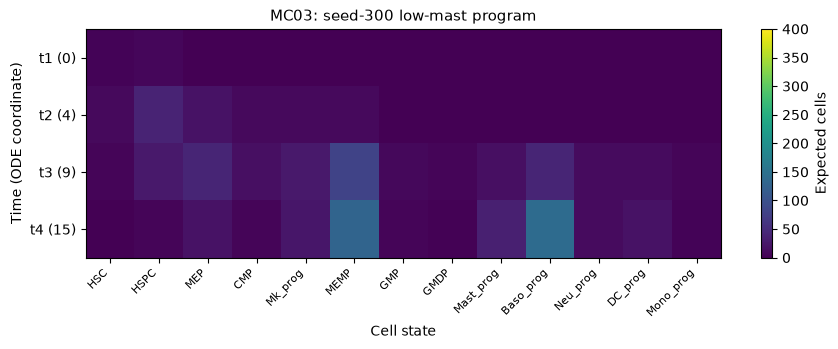

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Set Random Seed and Generate Parameters
# ---------------------------------------------------------

# Set seed for parameter generation (matches MATLAB rng(300))
np.random.seed(300)

# Generate parameters with random noise
p_hsc = 0.2 + np.random.randn() * 0.02
d_hsc = 0.1 + np.random.randn() * 0.01
m_hsc = 0.02 + np.random.randn() * 0.002

p_hspc = 0.3 + np.random.randn() * 0.03
d_hspc = 0.1 + np.random.randn() * 0.01
m_hspc = 0.011 + np.random.randn() * 0.0011

p_mep = 0.41 + np.random.randn() * 0.041
d_mep = 0.11 + np.random.randn() * 0.011
m_mep = 0.012 + np.random.randn() * 0.0012

p_cmp = 0.2 + np.random.randn() * 0.02
d_cmp = 0.09 + np.random.randn() * 0.009
m_cmp = 0.02 + np.random.randn() * 0.002

p_mk = 0.29 + np.random.randn() * 0.029
m_mk = 0.02 + np.random.randn() * 0.002

p_memp = 0.6 + np.random.randn() * 0.06
d_memp = 0.1 + np.random.randn() * 0.01
m_memp = 0.015 + np.random.randn() * 0.0015

p_gmp = 0.5 + np.random.randn() * 0.05
d_gmp = 0.3 + np.random.randn() * 0.03
m_gmp = 0.018 + np.random.randn() * 0.0018

p_gmdp = 0.4 + np.random.randn() * 0.04
d_gmdp = 0.3 + np.random.randn() * 0.03
m_gmdp = 0.071 + np.random.randn() * 0.0071

p_mast = 0.2 + np.random.randn() * 0.06
m_mast = 0.08 + np.random.randn() * 0.008

p_baso = 0.51 + np.random.randn() * 0.051
m_baso = 0.02 + np.random.randn() * 0.002

p_neu = 0.3 + np.random.randn() * 0.03
m_neu = 0.133 + np.random.randn() * 0.0133

p_dc = 0.6 + np.random.randn() * 0.06
m_dc = 0.11 + np.random.randn() * 0.011

p_mono = 0.145 + np.random.randn() * 0.0145
m_mono = 0.012 + np.random.randn() * 0.0012

print("Generated parameters:")
print(f"p_hsc={p_hsc:.4f}, d_hsc={d_hsc:.4f}, m_hsc={m_hsc:.4f}")
print(f"p_hspc={p_hspc:.4f}, d_hspc={d_hspc:.4f}, m_hspc={m_hspc:.4f}")

# ---------------------------------------------------------
# 2. Define ODE System with Generated Parameters
# ---------------------------------------------------------

def hematopoietic_model(t, y):
    dydt = np.zeros_like(y)
    x = y 

    # ODE Equations (using globally generated parameters)
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    return dydt

# ---------------------------------------------------------
# 3. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
t_plot = np.linspace(0, 20, 2001)

# Initial Conditions: HSC=1, HSPC=2, others=0
I0 = np.zeros(13)
I0[0] = 1.0  # HSC
I0[1] = 2.0  # HSPC

# ---------------------------------------------------------
# 4. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)

# Target sums for each timepoint: [10, 100, 300, 400]
target_sums = np.array([10, 100, 300, 400]).reshape(-1, 1)

# Normalize and Scale: (Model / Current_Sum) * Target_Sum
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------


# Record this program, verify its exact expected counts, and draw one profile heatmap.
program_number=3
program_id=f'MC{program_number:02d}'
program_clone_count=50
program_seed=300
program_rates={name:float(globals()[name]) for name in ['p_hsc', 'd_hsc', 'm_hsc', 'p_hspc', 'd_hspc', 'm_hspc', 'p_mep', 'd_mep', 'm_mep', 'p_cmp', 'd_cmp', 'm_cmp', 'p_mk', 'm_mk', 'p_memp', 'd_memp', 'm_memp', 'p_gmp', 'd_gmp', 'm_gmp', 'p_gmdp', 'd_gmdp', 'm_gmdp', 'p_mast', 'm_mast', 'p_baso', 'm_baso', 'p_neu', 'm_neu', 'p_dc', 'm_dc', 'p_mono', 'm_mono']}
rate_expressions={'p_hsc': '0.2 + np.random.randn() * 0.02', 'd_hsc': '0.1 + np.random.randn() * 0.01', 'm_hsc': '0.02 + np.random.randn() * 0.002', 'p_hspc': '0.3 + np.random.randn() * 0.03', 'd_hspc': '0.1 + np.random.randn() * 0.01', 'm_hspc': '0.011 + np.random.randn() * 0.0011', 'p_mep': '0.41 + np.random.randn() * 0.041', 'd_mep': '0.11 + np.random.randn() * 0.011', 'm_mep': '0.012 + np.random.randn() * 0.0012', 'p_cmp': '0.2 + np.random.randn() * 0.02', 'd_cmp': '0.09 + np.random.randn() * 0.009', 'm_cmp': '0.02 + np.random.randn() * 0.002', 'p_mk': '0.29 + np.random.randn() * 0.029', 'm_mk': '0.02 + np.random.randn() * 0.002', 'p_memp': '0.6 + np.random.randn() * 0.06', 'd_memp': '0.1 + np.random.randn() * 0.01', 'm_memp': '0.015 + np.random.randn() * 0.0015', 'p_gmp': '0.5 + np.random.randn() * 0.05', 'd_gmp': '0.3 + np.random.randn() * 0.03', 'm_gmp': '0.018 + np.random.randn() * 0.0018', 'p_gmdp': '0.4 + np.random.randn() * 0.04', 'd_gmdp': '0.3 + np.random.randn() * 0.03', 'm_gmdp': '0.071 + np.random.randn() * 0.0071', 'p_mast': '0.2 + np.random.randn() * 0.06', 'm_mast': '0.08 + np.random.randn() * 0.008', 'p_baso': '0.51 + np.random.randn() * 0.051', 'm_baso': '0.02 + np.random.randn() * 0.002', 'p_neu': '0.3 + np.random.randn() * 0.03', 'm_neu': '0.133 + np.random.randn() * 0.0133', 'p_dc': '0.6 + np.random.randn() * 0.06', 'm_dc': '0.11 + np.random.randn() * 0.011', 'p_mono': '0.145 + np.random.randn() * 0.0145', 'm_mono': '0.012 + np.random.randn() * 0.0012'}
ode_equations='def hematopoietic_model(t, y):\n    dydt = np.zeros_like(y)\n    x = y \n\n    # ODE Equations (using globally generated parameters)\n    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] \n    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]\n    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]\n    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]\n    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]\n    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]\n    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]\n    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]\n    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]\n    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]\n    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]\n    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]\n    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]\n\n    return dydt'
source_record={'program': 'MC03', 'historical_notebook': 'simulation_generate.ipynb', 'historical_notebook_sha256': 'a35588c48c547954c48c14d5def17da4b3ed1238a281cf78d20473e1c48a2cea', 'historical_cell_zero_based': 6, 'deterministic_prefix_sha256': 'f0936e5060aa95bfbe03445c73e57e76c9c896fd3b7edf535f34e079b2f89890', 'boundary': 'before # Calculate deviation', 'n_clones': 50, 'parameter_seed': 300}
assert sol_sample.success and sol_plot.success
profile=np.asarray(model_deterministic,dtype=np.float64).copy()
assert profile.shape==(4,13) and np.isfinite(profile).all() and (profile>=0).all()
assert np.array_equal(time_points,np.array([0,4,9,15]))
assert np.array_equal(profile,canonical_profiles[program_number-1]),program_id
assert program_clone_count==int(canonical_manifest.iloc[program_number-1]['n_clones'])
profiles.append(profile)
description=str(canonical_manifest.iloc[program_number-1]['description'])
program_record=dict(source_record,description=description,initial_conditions=I0.tolist(),
                    sampling_coordinates=time_points.tolist(),target_sums=target_sums.ravel().tolist(),
                    solver='RK45',solver_defaults=rk45_defaults,rate_values=program_rates,
                    rate_expressions=rate_expressions,ode_equations=ode_equations,
                    transformation='round sampled ODE values to nearest even, then rescale each timepoint to its target total')
program_records.append(program_record)
parameter_records.extend({'program':program_id,'parameter':name,'value':float(value),
                          'expression':rate_expressions[name],'parameter_seed':program_seed}
                         for name,value in program_rates.items())
equivalence_records.append({'program':program_id,'n_clones':program_clone_count,
                            'exact_profile_match':True,'maximum_absolute_difference':float(np.max(np.abs(profile-canonical_profiles[program_number-1])))})
display(pd.DataFrame(profile,index=TIME_LABELS,columns=STATES))

with mpl.rc_context({'svg.fonttype':'none','pdf.fonttype':42,'font.family':'DejaVu Sans'}):
    fig,ax=plt.subplots(figsize=(9,3.6))
    image=ax.imshow(profile,aspect='auto',cmap='viridis',vmin=0,
                    vmax=float(canonical_profiles.max()),interpolation='nearest')
    ax.set_xticks(np.arange(len(STATES)))
    ax.set_xticklabels(STATES,rotation=45,ha='right',fontsize=8)
    ax.set_yticks(np.arange(len(TIME_LABELS)))
    ax.set_yticklabels([f'{label} ({coordinate})' for label,coordinate in zip(TIME_LABELS,time_points)])
    ax.set_xlabel('Cell state')
    ax.set_ylabel('Time (ODE coordinate)')
    ax.set_title(f'{program_id}: {description}',fontsize=11)
    fig.colorbar(image,ax=ax,label='Expected cells')
    fig.tight_layout()
    stem=FIGURES/f'{program_id.lower()}_deterministic_profile'
    fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'),dpi=180,bbox_inches='tight')
    display(fig)
plt.close(fig)
figure_records.append({'program':program_id,'svg':str(stem.with_suffix('.svg').relative_to(BENCHMARK)),
                       'svg_sha256':sha(stem.with_suffix('.svg')),
                       'png':str(stem.with_suffix('.png').relative_to(BENCHMARK)),
                       'png_sha256':sha(stem.with_suffix('.png'))})


## Program 4

The complete deterministic calculation and its profile plot are in one cell. The result is checked against the corresponding registered program before export.

Generated parameters:
p_hsc=0.1774, d_hsc=0.1070, m_hsc=0.0191
p_hspc=0.3222, d_hspc=0.0952, m_hspc=0.0125


,HSC,HSPC,MEP,CMP,Mk_prog,MEMP,GMP,GMDP,Mast_prog,Baso_prog,Neu_prog,DC_prog,Mono_prog
t1,3.333333,6.666667,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
t2,8.333333,41.666667,16.666667,16.666667,8.333333,8.333333,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
t3,4.255319,36.170213,40.425532,19.148936,23.404255,80.851064,8.510638,6.382979,31.914894,27.659574,6.382979,10.638298,4.255319
t4,0.259151,8.422417,19.177195,5.442177,19.436346,137.479754,5.183026,2.202786,101.846453,75.672174,6.219631,15.419501,3.239391


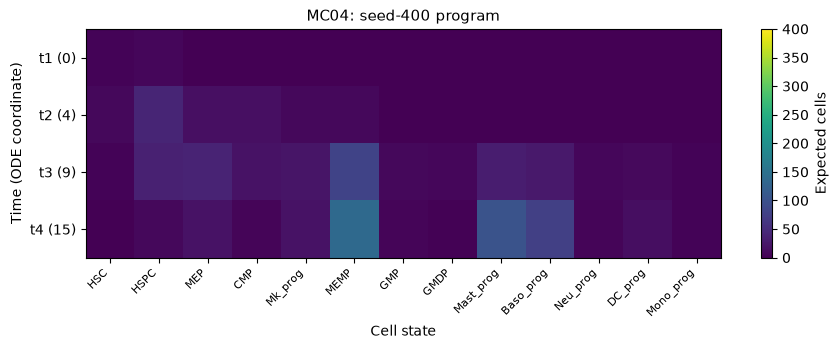

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Set Random Seed and Generate Parameters
# ---------------------------------------------------------

# Set seed for parameter generation (matches MATLAB rng(300))
np.random.seed(400)

# Generate parameters with random noise
p_hsc = 0.2 + np.random.randn() * 0.02
d_hsc = 0.1 + np.random.randn() * 0.01
m_hsc = 0.02 + np.random.randn() * 0.002

p_hspc = 0.3 + np.random.randn() * 0.03
d_hspc = 0.1 + np.random.randn() * 0.01
m_hspc = 0.011 + np.random.randn() * 0.0011

p_mep = 0.41 + np.random.randn() * 0.041
d_mep = 0.11 + np.random.randn() * 0.011
m_mep = 0.012 + np.random.randn() * 0.0012

p_cmp = 0.2 + np.random.randn() * 0.02
d_cmp = 0.09 + np.random.randn() * 0.009
m_cmp = 0.02 + np.random.randn() * 0.002

p_mk = 0.29 + np.random.randn() * 0.029
m_mk = 0.02 + np.random.randn() * 0.002

p_memp = 0.6 + np.random.randn() * 0.06
d_memp = 0.1 + np.random.randn() * 0.01
m_memp = 0.015 + np.random.randn() * 0.0015

p_gmp = 0.5 + np.random.randn() * 0.05
d_gmp = 0.3 + np.random.randn() * 0.03
m_gmp = 0.018 + np.random.randn() * 0.0018

p_gmdp = 0.4 + np.random.randn() * 0.04
d_gmdp = 0.3 + np.random.randn() * 0.03
m_gmdp = 0.071 + np.random.randn() * 0.0071

p_mast = 0.6 + np.random.randn() * 0.06
m_mast = 0.08 + np.random.randn() * 0.008

p_baso = 0.51 + np.random.randn() * 0.051
m_baso = 0.02 + np.random.randn() * 0.002

p_neu = 0.3 + np.random.randn() * 0.03
m_neu = 0.133 + np.random.randn() * 0.0133

p_dc = 0.6 + np.random.randn() * 0.06
m_dc = 0.11 + np.random.randn() * 0.011

p_mono = 0.145 + np.random.randn() * 0.0145
m_mono = 0.012 + np.random.randn() * 0.0012

print("Generated parameters:")
print(f"p_hsc={p_hsc:.4f}, d_hsc={d_hsc:.4f}, m_hsc={m_hsc:.4f}")
print(f"p_hspc={p_hspc:.4f}, d_hspc={d_hspc:.4f}, m_hspc={m_hspc:.4f}")

# ---------------------------------------------------------
# 2. Define ODE System with Generated Parameters
# ---------------------------------------------------------

def hematopoietic_model(t, y):
    dydt = np.zeros_like(y)
    x = y 

    # ODE Equations (using globally generated parameters)
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    return dydt

# ---------------------------------------------------------
# 3. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
t_plot = np.linspace(0, 20, 2001)

# Initial Conditions: HSC=1, HSPC=2, others=0
I0 = np.zeros(13)
I0[0] = 1.0  # HSC
I0[1] = 2.0  # HSPC

# ---------------------------------------------------------
# 4. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)

# Target sums for each timepoint: [10, 100, 300, 400]
target_sums = np.array([10, 100, 300, 400]).reshape(-1, 1)

# Normalize and Scale: (Model / Current_Sum) * Target_Sum
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------


# Record this program, verify its exact expected counts, and draw one profile heatmap.
program_number=4
program_id=f'MC{program_number:02d}'
program_clone_count=40
program_seed=400
program_rates={name:float(globals()[name]) for name in ['p_hsc', 'd_hsc', 'm_hsc', 'p_hspc', 'd_hspc', 'm_hspc', 'p_mep', 'd_mep', 'm_mep', 'p_cmp', 'd_cmp', 'm_cmp', 'p_mk', 'm_mk', 'p_memp', 'd_memp', 'm_memp', 'p_gmp', 'd_gmp', 'm_gmp', 'p_gmdp', 'd_gmdp', 'm_gmdp', 'p_mast', 'm_mast', 'p_baso', 'm_baso', 'p_neu', 'm_neu', 'p_dc', 'm_dc', 'p_mono', 'm_mono']}
rate_expressions={'p_hsc': '0.2 + np.random.randn() * 0.02', 'd_hsc': '0.1 + np.random.randn() * 0.01', 'm_hsc': '0.02 + np.random.randn() * 0.002', 'p_hspc': '0.3 + np.random.randn() * 0.03', 'd_hspc': '0.1 + np.random.randn() * 0.01', 'm_hspc': '0.011 + np.random.randn() * 0.0011', 'p_mep': '0.41 + np.random.randn() * 0.041', 'd_mep': '0.11 + np.random.randn() * 0.011', 'm_mep': '0.012 + np.random.randn() * 0.0012', 'p_cmp': '0.2 + np.random.randn() * 0.02', 'd_cmp': '0.09 + np.random.randn() * 0.009', 'm_cmp': '0.02 + np.random.randn() * 0.002', 'p_mk': '0.29 + np.random.randn() * 0.029', 'm_mk': '0.02 + np.random.randn() * 0.002', 'p_memp': '0.6 + np.random.randn() * 0.06', 'd_memp': '0.1 + np.random.randn() * 0.01', 'm_memp': '0.015 + np.random.randn() * 0.0015', 'p_gmp': '0.5 + np.random.randn() * 0.05', 'd_gmp': '0.3 + np.random.randn() * 0.03', 'm_gmp': '0.018 + np.random.randn() * 0.0018', 'p_gmdp': '0.4 + np.random.randn() * 0.04', 'd_gmdp': '0.3 + np.random.randn() * 0.03', 'm_gmdp': '0.071 + np.random.randn() * 0.0071', 'p_mast': '0.6 + np.random.randn() * 0.06', 'm_mast': '0.08 + np.random.randn() * 0.008', 'p_baso': '0.51 + np.random.randn() * 0.051', 'm_baso': '0.02 + np.random.randn() * 0.002', 'p_neu': '0.3 + np.random.randn() * 0.03', 'm_neu': '0.133 + np.random.randn() * 0.0133', 'p_dc': '0.6 + np.random.randn() * 0.06', 'm_dc': '0.11 + np.random.randn() * 0.011', 'p_mono': '0.145 + np.random.randn() * 0.0145', 'm_mono': '0.012 + np.random.randn() * 0.0012'}
ode_equations='def hematopoietic_model(t, y):\n    dydt = np.zeros_like(y)\n    x = y \n\n    # ODE Equations (using globally generated parameters)\n    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] \n    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]\n    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]\n    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]\n    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]\n    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]\n    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]\n    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]\n    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]\n    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]\n    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]\n    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]\n    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]\n\n    return dydt'
source_record={'program': 'MC04', 'historical_notebook': 'simulation_generate.ipynb', 'historical_notebook_sha256': 'a35588c48c547954c48c14d5def17da4b3ed1238a281cf78d20473e1c48a2cea', 'historical_cell_zero_based': 8, 'deterministic_prefix_sha256': '6932cc7bb08a3ab1c48b3ab147df26a344b34ac5539617188b5a7434f83c11d9', 'boundary': 'before # Calculate deviation', 'n_clones': 40, 'parameter_seed': 400}
assert sol_sample.success and sol_plot.success
profile=np.asarray(model_deterministic,dtype=np.float64).copy()
assert profile.shape==(4,13) and np.isfinite(profile).all() and (profile>=0).all()
assert np.array_equal(time_points,np.array([0,4,9,15]))
assert np.array_equal(profile,canonical_profiles[program_number-1]),program_id
assert program_clone_count==int(canonical_manifest.iloc[program_number-1]['n_clones'])
profiles.append(profile)
description=str(canonical_manifest.iloc[program_number-1]['description'])
program_record=dict(source_record,description=description,initial_conditions=I0.tolist(),
                    sampling_coordinates=time_points.tolist(),target_sums=target_sums.ravel().tolist(),
                    solver='RK45',solver_defaults=rk45_defaults,rate_values=program_rates,
                    rate_expressions=rate_expressions,ode_equations=ode_equations,
                    transformation='round sampled ODE values to nearest even, then rescale each timepoint to its target total')
program_records.append(program_record)
parameter_records.extend({'program':program_id,'parameter':name,'value':float(value),
                          'expression':rate_expressions[name],'parameter_seed':program_seed}
                         for name,value in program_rates.items())
equivalence_records.append({'program':program_id,'n_clones':program_clone_count,
                            'exact_profile_match':True,'maximum_absolute_difference':float(np.max(np.abs(profile-canonical_profiles[program_number-1])))})
display(pd.DataFrame(profile,index=TIME_LABELS,columns=STATES))

with mpl.rc_context({'svg.fonttype':'none','pdf.fonttype':42,'font.family':'DejaVu Sans'}):
    fig,ax=plt.subplots(figsize=(9,3.6))
    image=ax.imshow(profile,aspect='auto',cmap='viridis',vmin=0,
                    vmax=float(canonical_profiles.max()),interpolation='nearest')
    ax.set_xticks(np.arange(len(STATES)))
    ax.set_xticklabels(STATES,rotation=45,ha='right',fontsize=8)
    ax.set_yticks(np.arange(len(TIME_LABELS)))
    ax.set_yticklabels([f'{label} ({coordinate})' for label,coordinate in zip(TIME_LABELS,time_points)])
    ax.set_xlabel('Cell state')
    ax.set_ylabel('Time (ODE coordinate)')
    ax.set_title(f'{program_id}: {description}',fontsize=11)
    fig.colorbar(image,ax=ax,label='Expected cells')
    fig.tight_layout()
    stem=FIGURES/f'{program_id.lower()}_deterministic_profile'
    fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'),dpi=180,bbox_inches='tight')
    display(fig)
plt.close(fig)
figure_records.append({'program':program_id,'svg':str(stem.with_suffix('.svg').relative_to(BENCHMARK)),
                       'svg_sha256':sha(stem.with_suffix('.svg')),
                       'png':str(stem.with_suffix('.png').relative_to(BENCHMARK)),
                       'png_sha256':sha(stem.with_suffix('.png'))})


## Program 5

The complete deterministic calculation and its profile plot are in one cell. The result is checked against the corresponding registered program before export.

Generated parameters:
p_hsc=0.1925, d_hsc=0.1017, m_hsc=0.0214
p_hspc=0.3576, d_hspc=0.0980, m_hspc=0.0102


,HSC,HSPC,MEP,CMP,Mk_prog,MEMP,GMP,GMDP,Mast_prog,Baso_prog,Neu_prog,DC_prog,Mono_prog
t1,3.333333,6.666667,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
t2,8.333333,50.000000,16.666667,16.666667,0.000000,8.333333,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
t3,3.947368,45.394737,31.578947,17.763158,15.789474,75.000000,7.894737,5.921053,39.473684,29.605263,5.921053,17.763158,3.947368
t4,0.282021,10.058754,10.152761,4.794360,8.554642,111.304348,2.726204,1.974148,129.917744,81.598120,4.324324,31.774383,2.538190


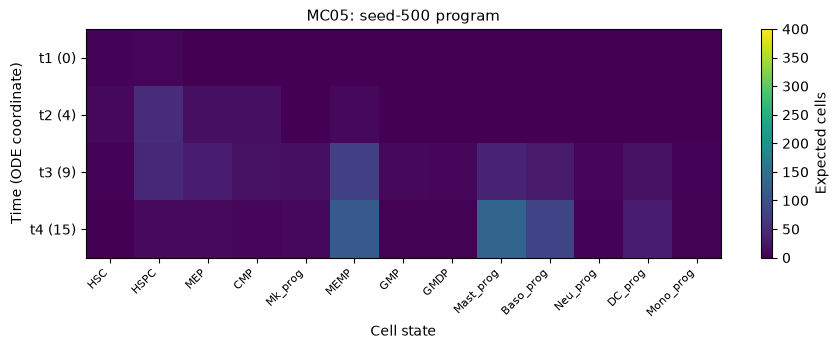

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Set Random Seed and Generate Parameters
# ---------------------------------------------------------

# Set seed for parameter generation (matches MATLAB rng(300))
np.random.seed(500)

# Generate parameters with random noise
p_hsc = 0.2 + np.random.randn() * 0.02
d_hsc = 0.1 + np.random.randn() * 0.01
m_hsc = 0.02 + np.random.randn() * 0.002

p_hspc = 0.3 + np.random.randn() * 0.03
d_hspc = 0.1 + np.random.randn() * 0.01
m_hspc = 0.011 + np.random.randn() * 0.0011

p_mep = 0.41 + np.random.randn() * 0.041
d_mep = 0.11 + np.random.randn() * 0.011
m_mep = 0.012 + np.random.randn() * 0.0012

p_cmp = 0.2 + np.random.randn() * 0.02
d_cmp = 0.09 + np.random.randn() * 0.009
m_cmp = 0.02 + np.random.randn() * 0.002

p_mk = 0.29 + np.random.randn() * 0.029
m_mk = 0.02 + np.random.randn() * 0.002

p_memp = 0.6 + np.random.randn() * 0.06
d_memp = 0.1 + np.random.randn() * 0.01
m_memp = 0.015 + np.random.randn() * 0.0015

p_gmp = 0.5 + np.random.randn() * 0.05
d_gmp = 0.3 + np.random.randn() * 0.03
m_gmp = 0.018 + np.random.randn() * 0.0018

p_gmdp = 0.4 + np.random.randn() * 0.04
d_gmdp = 0.3 + np.random.randn() * 0.03
m_gmdp = 0.071 + np.random.randn() * 0.0071

p_mast = 0.6 + np.random.randn() * 0.06
m_mast = 0.08 + np.random.randn() * 0.008

p_baso = 0.51 + np.random.randn() * 0.051
m_baso = 0.02 + np.random.randn() * 0.002

p_neu = 0.3 + np.random.randn() * 0.03
m_neu = 0.133 + np.random.randn() * 0.0133

p_dc = 0.6 + np.random.randn() * 0.06
m_dc = 0.11 + np.random.randn() * 0.011

p_mono = 0.145 + np.random.randn() * 0.0145
m_mono = 0.012 + np.random.randn() * 0.0012

print("Generated parameters:")
print(f"p_hsc={p_hsc:.4f}, d_hsc={d_hsc:.4f}, m_hsc={m_hsc:.4f}")
print(f"p_hspc={p_hspc:.4f}, d_hspc={d_hspc:.4f}, m_hspc={m_hspc:.4f}")

# ---------------------------------------------------------
# 2. Define ODE System with Generated Parameters
# ---------------------------------------------------------

def hematopoietic_model(t, y):
    dydt = np.zeros_like(y)
    x = y 

    # ODE Equations (using globally generated parameters)
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    return dydt

# ---------------------------------------------------------
# 3. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
t_plot = np.linspace(0, 20, 2001)

# Initial Conditions: HSC=1, HSPC=2, others=0
I0 = np.zeros(13)
I0[0] = 1.0  # HSC
I0[1] = 2.0  # HSPC

# ---------------------------------------------------------
# 4. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)

# Target sums for each timepoint: [10, 100, 300, 400]
target_sums = np.array([10, 100, 300, 400]).reshape(-1, 1)

# Normalize and Scale: (Model / Current_Sum) * Target_Sum
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------


# Record this program, verify its exact expected counts, and draw one profile heatmap.
program_number=5
program_id=f'MC{program_number:02d}'
program_clone_count=72
program_seed=500
program_rates={name:float(globals()[name]) for name in ['p_hsc', 'd_hsc', 'm_hsc', 'p_hspc', 'd_hspc', 'm_hspc', 'p_mep', 'd_mep', 'm_mep', 'p_cmp', 'd_cmp', 'm_cmp', 'p_mk', 'm_mk', 'p_memp', 'd_memp', 'm_memp', 'p_gmp', 'd_gmp', 'm_gmp', 'p_gmdp', 'd_gmdp', 'm_gmdp', 'p_mast', 'm_mast', 'p_baso', 'm_baso', 'p_neu', 'm_neu', 'p_dc', 'm_dc', 'p_mono', 'm_mono']}
rate_expressions={'p_hsc': '0.2 + np.random.randn() * 0.02', 'd_hsc': '0.1 + np.random.randn() * 0.01', 'm_hsc': '0.02 + np.random.randn() * 0.002', 'p_hspc': '0.3 + np.random.randn() * 0.03', 'd_hspc': '0.1 + np.random.randn() * 0.01', 'm_hspc': '0.011 + np.random.randn() * 0.0011', 'p_mep': '0.41 + np.random.randn() * 0.041', 'd_mep': '0.11 + np.random.randn() * 0.011', 'm_mep': '0.012 + np.random.randn() * 0.0012', 'p_cmp': '0.2 + np.random.randn() * 0.02', 'd_cmp': '0.09 + np.random.randn() * 0.009', 'm_cmp': '0.02 + np.random.randn() * 0.002', 'p_mk': '0.29 + np.random.randn() * 0.029', 'm_mk': '0.02 + np.random.randn() * 0.002', 'p_memp': '0.6 + np.random.randn() * 0.06', 'd_memp': '0.1 + np.random.randn() * 0.01', 'm_memp': '0.015 + np.random.randn() * 0.0015', 'p_gmp': '0.5 + np.random.randn() * 0.05', 'd_gmp': '0.3 + np.random.randn() * 0.03', 'm_gmp': '0.018 + np.random.randn() * 0.0018', 'p_gmdp': '0.4 + np.random.randn() * 0.04', 'd_gmdp': '0.3 + np.random.randn() * 0.03', 'm_gmdp': '0.071 + np.random.randn() * 0.0071', 'p_mast': '0.6 + np.random.randn() * 0.06', 'm_mast': '0.08 + np.random.randn() * 0.008', 'p_baso': '0.51 + np.random.randn() * 0.051', 'm_baso': '0.02 + np.random.randn() * 0.002', 'p_neu': '0.3 + np.random.randn() * 0.03', 'm_neu': '0.133 + np.random.randn() * 0.0133', 'p_dc': '0.6 + np.random.randn() * 0.06', 'm_dc': '0.11 + np.random.randn() * 0.011', 'p_mono': '0.145 + np.random.randn() * 0.0145', 'm_mono': '0.012 + np.random.randn() * 0.0012'}
ode_equations='def hematopoietic_model(t, y):\n    dydt = np.zeros_like(y)\n    x = y \n\n    # ODE Equations (using globally generated parameters)\n    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] \n    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]\n    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]\n    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]\n    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]\n    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]\n    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]\n    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]\n    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]\n    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]\n    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]\n    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]\n    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]\n\n    return dydt'
source_record={'program': 'MC05', 'historical_notebook': 'simulation_generate.ipynb', 'historical_notebook_sha256': 'a35588c48c547954c48c14d5def17da4b3ed1238a281cf78d20473e1c48a2cea', 'historical_cell_zero_based': 10, 'deterministic_prefix_sha256': 'c3f858c20e9d87b7545fcc5b10220aa9ec502c429757c8a6d3c1532332c27bb7', 'boundary': 'before # Calculate deviation', 'n_clones': 72, 'parameter_seed': 500}
assert sol_sample.success and sol_plot.success
profile=np.asarray(model_deterministic,dtype=np.float64).copy()
assert profile.shape==(4,13) and np.isfinite(profile).all() and (profile>=0).all()
assert np.array_equal(time_points,np.array([0,4,9,15]))
assert np.array_equal(profile,canonical_profiles[program_number-1]),program_id
assert program_clone_count==int(canonical_manifest.iloc[program_number-1]['n_clones'])
profiles.append(profile)
description=str(canonical_manifest.iloc[program_number-1]['description'])
program_record=dict(source_record,description=description,initial_conditions=I0.tolist(),
                    sampling_coordinates=time_points.tolist(),target_sums=target_sums.ravel().tolist(),
                    solver='RK45',solver_defaults=rk45_defaults,rate_values=program_rates,
                    rate_expressions=rate_expressions,ode_equations=ode_equations,
                    transformation='round sampled ODE values to nearest even, then rescale each timepoint to its target total')
program_records.append(program_record)
parameter_records.extend({'program':program_id,'parameter':name,'value':float(value),
                          'expression':rate_expressions[name],'parameter_seed':program_seed}
                         for name,value in program_rates.items())
equivalence_records.append({'program':program_id,'n_clones':program_clone_count,
                            'exact_profile_match':True,'maximum_absolute_difference':float(np.max(np.abs(profile-canonical_profiles[program_number-1])))})
display(pd.DataFrame(profile,index=TIME_LABELS,columns=STATES))

with mpl.rc_context({'svg.fonttype':'none','pdf.fonttype':42,'font.family':'DejaVu Sans'}):
    fig,ax=plt.subplots(figsize=(9,3.6))
    image=ax.imshow(profile,aspect='auto',cmap='viridis',vmin=0,
                    vmax=float(canonical_profiles.max()),interpolation='nearest')
    ax.set_xticks(np.arange(len(STATES)))
    ax.set_xticklabels(STATES,rotation=45,ha='right',fontsize=8)
    ax.set_yticks(np.arange(len(TIME_LABELS)))
    ax.set_yticklabels([f'{label} ({coordinate})' for label,coordinate in zip(TIME_LABELS,time_points)])
    ax.set_xlabel('Cell state')
    ax.set_ylabel('Time (ODE coordinate)')
    ax.set_title(f'{program_id}: {description}',fontsize=11)
    fig.colorbar(image,ax=ax,label='Expected cells')
    fig.tight_layout()
    stem=FIGURES/f'{program_id.lower()}_deterministic_profile'
    fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'),dpi=180,bbox_inches='tight')
    display(fig)
plt.close(fig)
figure_records.append({'program':program_id,'svg':str(stem.with_suffix('.svg').relative_to(BENCHMARK)),
                       'svg_sha256':sha(stem.with_suffix('.svg')),
                       'png':str(stem.with_suffix('.png').relative_to(BENCHMARK)),
                       'png_sha256':sha(stem.with_suffix('.png'))})


## Program 6

The complete deterministic calculation and its profile plot are in one cell. The result is checked against the corresponding registered program before export.

Generated parameters:
p_hsc=0.2009, d_hsc=0.0950, m_hsc=0.0175
p_hspc=0.2845, d_hspc=0.1051, m_hspc=0.0107


,HSC,HSPC,MEP,CMP,Mk_prog,MEMP,GMP,GMDP,Mast_prog,Baso_prog,Neu_prog,DC_prog,Mono_prog
t1,3.333333,6.666667,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
t2,9.090909,45.454545,18.181818,18.181818,0.000000,9.090909,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
t3,5.217391,31.304348,44.347826,20.869565,23.478261,60.000000,7.826087,7.826087,31.304348,33.913043,7.826087,20.869565,5.217391
t4,0.725953,6.533575,23.049002,6.170599,21.415608,74.773140,4.718693,3.992740,83.666062,105.263158,6.896552,58.439201,4.355717


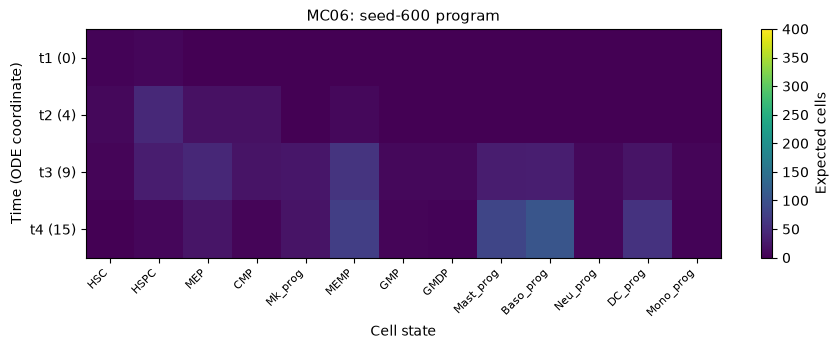

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Set Random Seed and Generate Parameters
# ---------------------------------------------------------

# Set seed for parameter generation (matches MATLAB rng(300))
np.random.seed(600)

# Generate parameters with random noise
p_hsc = 0.2 + np.random.randn() * 0.02
d_hsc = 0.1 + np.random.randn() * 0.01
m_hsc = 0.02 + np.random.randn() * 0.002

p_hspc = 0.3 + np.random.randn() * 0.03
d_hspc = 0.1 + np.random.randn() * 0.01
m_hspc = 0.011 + np.random.randn() * 0.0011

p_mep = 0.41 + np.random.randn() * 0.041
d_mep = 0.11 + np.random.randn() * 0.011
m_mep = 0.012 + np.random.randn() * 0.0012

p_cmp = 0.2 + np.random.randn() * 0.02
d_cmp = 0.09 + np.random.randn() * 0.009
m_cmp = 0.02 + np.random.randn() * 0.002

p_mk = 0.29 + np.random.randn() * 0.029
m_mk = 0.02 + np.random.randn() * 0.002

p_memp = 0.6 + np.random.randn() * 0.06
d_memp = 0.1 + np.random.randn() * 0.01
m_memp = 0.015 + np.random.randn() * 0.0015

p_gmp = 0.5 + np.random.randn() * 0.05
d_gmp = 0.3 + np.random.randn() * 0.03
m_gmp = 0.018 + np.random.randn() * 0.0018

p_gmdp = 0.4 + np.random.randn() * 0.04
d_gmdp = 0.3 + np.random.randn() * 0.03
m_gmdp = 0.071 + np.random.randn() * 0.0071

p_mast = 0.6 + np.random.randn() * 0.06
m_mast = 0.08 + np.random.randn() * 0.008

p_baso = 0.51 + np.random.randn() * 0.051
m_baso = 0.02 + np.random.randn() * 0.002

p_neu = 0.3 + np.random.randn() * 0.03
m_neu = 0.133 + np.random.randn() * 0.0133

p_dc = 0.6 + np.random.randn() * 0.06
m_dc = 0.11 + np.random.randn() * 0.011

p_mono = 0.145 + np.random.randn() * 0.0145
m_mono = 0.012 + np.random.randn() * 0.0012

print("Generated parameters:")
print(f"p_hsc={p_hsc:.4f}, d_hsc={d_hsc:.4f}, m_hsc={m_hsc:.4f}")
print(f"p_hspc={p_hspc:.4f}, d_hspc={d_hspc:.4f}, m_hspc={m_hspc:.4f}")

# ---------------------------------------------------------
# 2. Define ODE System with Generated Parameters
# ---------------------------------------------------------

def hematopoietic_model(t, y):
    dydt = np.zeros_like(y)
    x = y 

    # ODE Equations (using globally generated parameters)
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    return dydt

# ---------------------------------------------------------
# 3. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
t_plot = np.linspace(0, 20, 2001)

# Initial Conditions: HSC=1, HSPC=2, others=0
I0 = np.zeros(13)
I0[0] = 1.0  # HSC
I0[1] = 2.0  # HSPC

# ---------------------------------------------------------
# 4. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)

# Target sums for each timepoint: [10, 100, 300, 400]
target_sums = np.array([10, 100, 300, 400]).reshape(-1, 1)

# Normalize and Scale: (Model / Current_Sum) * Target_Sum
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------


# Record this program, verify its exact expected counts, and draw one profile heatmap.
program_number=6
program_id=f'MC{program_number:02d}'
program_clone_count=56
program_seed=600
program_rates={name:float(globals()[name]) for name in ['p_hsc', 'd_hsc', 'm_hsc', 'p_hspc', 'd_hspc', 'm_hspc', 'p_mep', 'd_mep', 'm_mep', 'p_cmp', 'd_cmp', 'm_cmp', 'p_mk', 'm_mk', 'p_memp', 'd_memp', 'm_memp', 'p_gmp', 'd_gmp', 'm_gmp', 'p_gmdp', 'd_gmdp', 'm_gmdp', 'p_mast', 'm_mast', 'p_baso', 'm_baso', 'p_neu', 'm_neu', 'p_dc', 'm_dc', 'p_mono', 'm_mono']}
rate_expressions={'p_hsc': '0.2 + np.random.randn() * 0.02', 'd_hsc': '0.1 + np.random.randn() * 0.01', 'm_hsc': '0.02 + np.random.randn() * 0.002', 'p_hspc': '0.3 + np.random.randn() * 0.03', 'd_hspc': '0.1 + np.random.randn() * 0.01', 'm_hspc': '0.011 + np.random.randn() * 0.0011', 'p_mep': '0.41 + np.random.randn() * 0.041', 'd_mep': '0.11 + np.random.randn() * 0.011', 'm_mep': '0.012 + np.random.randn() * 0.0012', 'p_cmp': '0.2 + np.random.randn() * 0.02', 'd_cmp': '0.09 + np.random.randn() * 0.009', 'm_cmp': '0.02 + np.random.randn() * 0.002', 'p_mk': '0.29 + np.random.randn() * 0.029', 'm_mk': '0.02 + np.random.randn() * 0.002', 'p_memp': '0.6 + np.random.randn() * 0.06', 'd_memp': '0.1 + np.random.randn() * 0.01', 'm_memp': '0.015 + np.random.randn() * 0.0015', 'p_gmp': '0.5 + np.random.randn() * 0.05', 'd_gmp': '0.3 + np.random.randn() * 0.03', 'm_gmp': '0.018 + np.random.randn() * 0.0018', 'p_gmdp': '0.4 + np.random.randn() * 0.04', 'd_gmdp': '0.3 + np.random.randn() * 0.03', 'm_gmdp': '0.071 + np.random.randn() * 0.0071', 'p_mast': '0.6 + np.random.randn() * 0.06', 'm_mast': '0.08 + np.random.randn() * 0.008', 'p_baso': '0.51 + np.random.randn() * 0.051', 'm_baso': '0.02 + np.random.randn() * 0.002', 'p_neu': '0.3 + np.random.randn() * 0.03', 'm_neu': '0.133 + np.random.randn() * 0.0133', 'p_dc': '0.6 + np.random.randn() * 0.06', 'm_dc': '0.11 + np.random.randn() * 0.011', 'p_mono': '0.145 + np.random.randn() * 0.0145', 'm_mono': '0.012 + np.random.randn() * 0.0012'}
ode_equations='def hematopoietic_model(t, y):\n    dydt = np.zeros_like(y)\n    x = y \n\n    # ODE Equations (using globally generated parameters)\n    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] \n    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]\n    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]\n    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]\n    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]\n    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]\n    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]\n    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]\n    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]\n    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]\n    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]\n    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]\n    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]\n\n    return dydt'
source_record={'program': 'MC06', 'historical_notebook': 'simulation_generate.ipynb', 'historical_notebook_sha256': 'a35588c48c547954c48c14d5def17da4b3ed1238a281cf78d20473e1c48a2cea', 'historical_cell_zero_based': 12, 'deterministic_prefix_sha256': '271dcaa7c295d43d9ecdc1cd9fd1467540ec509e020918d22b02f304e9b5c045', 'boundary': 'before # Calculate deviation', 'n_clones': 56, 'parameter_seed': 600}
assert sol_sample.success and sol_plot.success
profile=np.asarray(model_deterministic,dtype=np.float64).copy()
assert profile.shape==(4,13) and np.isfinite(profile).all() and (profile>=0).all()
assert np.array_equal(time_points,np.array([0,4,9,15]))
assert np.array_equal(profile,canonical_profiles[program_number-1]),program_id
assert program_clone_count==int(canonical_manifest.iloc[program_number-1]['n_clones'])
profiles.append(profile)
description=str(canonical_manifest.iloc[program_number-1]['description'])
program_record=dict(source_record,description=description,initial_conditions=I0.tolist(),
                    sampling_coordinates=time_points.tolist(),target_sums=target_sums.ravel().tolist(),
                    solver='RK45',solver_defaults=rk45_defaults,rate_values=program_rates,
                    rate_expressions=rate_expressions,ode_equations=ode_equations,
                    transformation='round sampled ODE values to nearest even, then rescale each timepoint to its target total')
program_records.append(program_record)
parameter_records.extend({'program':program_id,'parameter':name,'value':float(value),
                          'expression':rate_expressions[name],'parameter_seed':program_seed}
                         for name,value in program_rates.items())
equivalence_records.append({'program':program_id,'n_clones':program_clone_count,
                            'exact_profile_match':True,'maximum_absolute_difference':float(np.max(np.abs(profile-canonical_profiles[program_number-1])))})
display(pd.DataFrame(profile,index=TIME_LABELS,columns=STATES))

with mpl.rc_context({'svg.fonttype':'none','pdf.fonttype':42,'font.family':'DejaVu Sans'}):
    fig,ax=plt.subplots(figsize=(9,3.6))
    image=ax.imshow(profile,aspect='auto',cmap='viridis',vmin=0,
                    vmax=float(canonical_profiles.max()),interpolation='nearest')
    ax.set_xticks(np.arange(len(STATES)))
    ax.set_xticklabels(STATES,rotation=45,ha='right',fontsize=8)
    ax.set_yticks(np.arange(len(TIME_LABELS)))
    ax.set_yticklabels([f'{label} ({coordinate})' for label,coordinate in zip(TIME_LABELS,time_points)])
    ax.set_xlabel('Cell state')
    ax.set_ylabel('Time (ODE coordinate)')
    ax.set_title(f'{program_id}: {description}',fontsize=11)
    fig.colorbar(image,ax=ax,label='Expected cells')
    fig.tight_layout()
    stem=FIGURES/f'{program_id.lower()}_deterministic_profile'
    fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'),dpi=180,bbox_inches='tight')
    display(fig)
plt.close(fig)
figure_records.append({'program':program_id,'svg':str(stem.with_suffix('.svg').relative_to(BENCHMARK)),
                       'svg_sha256':sha(stem.with_suffix('.svg')),
                       'png':str(stem.with_suffix('.png').relative_to(BENCHMARK)),
                       'png_sha256':sha(stem.with_suffix('.png'))})


## Program 7

The complete deterministic calculation and its profile plot are in one cell. The result is checked against the corresponding registered program before export.

Generated parameters:
p_hsc=0.1945, d_hsc=0.0885, m_hsc=0.0221
p_hspc=0.2739, d_hspc=0.0824, m_hspc=0.0099


,HSC,HSPC,MEP,CMP,Mk_prog,MEMP,GMP,GMDP,Mast_prog,Baso_prog,Neu_prog,DC_prog,Mono_prog
t1,3.333333,6.666667,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
t2,10.000000,50.000000,20.000000,10.000000,0.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
t3,4.109589,26.712329,41.095890,14.383562,20.547945,94.520548,6.164384,4.109589,34.931507,32.876712,6.164384,10.273973,4.109589
t4,0.340933,3.494566,16.450032,2.727466,13.552099,159.471553,1.875133,1.022800,97.933092,86.511826,2.983166,12.103132,1.534200


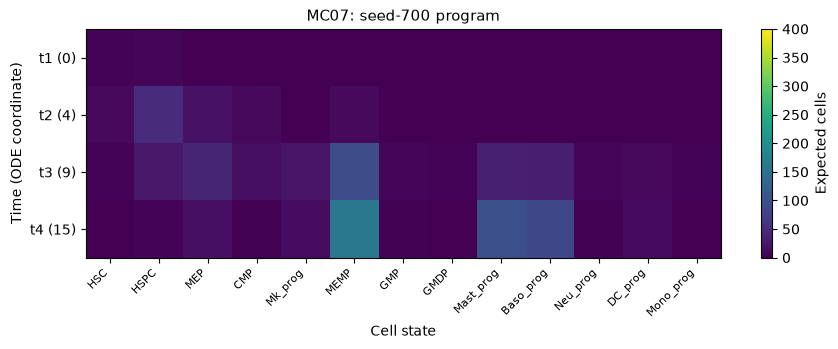

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Set Random Seed and Generate Parameters
# ---------------------------------------------------------

# Set seed for parameter generation (matches MATLAB rng(300))
np.random.seed(700)

# Generate parameters with random noise
p_hsc = 0.2 + np.random.randn() * 0.02
d_hsc = 0.1 + np.random.randn() * 0.01
m_hsc = 0.02 + np.random.randn() * 0.002

p_hspc = 0.3 + np.random.randn() * 0.03
d_hspc = 0.1 + np.random.randn() * 0.01
m_hspc = 0.011 + np.random.randn() * 0.0011

p_mep = 0.41 + np.random.randn() * 0.041
d_mep = 0.11 + np.random.randn() * 0.011
m_mep = 0.012 + np.random.randn() * 0.0012

p_cmp = 0.2 + np.random.randn() * 0.02
d_cmp = 0.09 + np.random.randn() * 0.009
m_cmp = 0.02 + np.random.randn() * 0.002

p_mk = 0.29 + np.random.randn() * 0.029
m_mk = 0.02 + np.random.randn() * 0.002

p_memp = 0.6 + np.random.randn() * 0.06
d_memp = 0.1 + np.random.randn() * 0.01
m_memp = 0.015 + np.random.randn() * 0.0015

p_gmp = 0.5 + np.random.randn() * 0.05
d_gmp = 0.3 + np.random.randn() * 0.03
m_gmp = 0.018 + np.random.randn() * 0.0018

p_gmdp = 0.4 + np.random.randn() * 0.04
d_gmdp = 0.3 + np.random.randn() * 0.03
m_gmdp = 0.071 + np.random.randn() * 0.0071

p_mast = 0.6 + np.random.randn() * 0.06
m_mast = 0.08 + np.random.randn() * 0.008

p_baso = 0.51 + np.random.randn() * 0.051
m_baso = 0.02 + np.random.randn() * 0.002

p_neu = 0.3 + np.random.randn() * 0.03
m_neu = 0.133 + np.random.randn() * 0.0133

p_dc = 0.6 + np.random.randn() * 0.06
m_dc = 0.11 + np.random.randn() * 0.011

p_mono = 0.145 + np.random.randn() * 0.0145
m_mono = 0.012 + np.random.randn() * 0.0012

print("Generated parameters:")
print(f"p_hsc={p_hsc:.4f}, d_hsc={d_hsc:.4f}, m_hsc={m_hsc:.4f}")
print(f"p_hspc={p_hspc:.4f}, d_hspc={d_hspc:.4f}, m_hspc={m_hspc:.4f}")

# ---------------------------------------------------------
# 2. Define ODE System with Generated Parameters
# ---------------------------------------------------------

def hematopoietic_model(t, y):
    dydt = np.zeros_like(y)
    x = y 

    # ODE Equations (using globally generated parameters)
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    return dydt

# ---------------------------------------------------------
# 3. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
t_plot = np.linspace(0, 20, 2001)

# Initial Conditions: HSC=1, HSPC=2, others=0
I0 = np.zeros(13)
I0[0] = 1.0  # HSC
I0[1] = 2.0  # HSPC

# ---------------------------------------------------------
# 4. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)

# Target sums for each timepoint: [10, 100, 300, 400]
target_sums = np.array([10, 100, 300, 400]).reshape(-1, 1)

# Normalize and Scale: (Model / Current_Sum) * Target_Sum
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------


# Record this program, verify its exact expected counts, and draw one profile heatmap.
program_number=7
program_id=f'MC{program_number:02d}'
program_clone_count=88
program_seed=700
program_rates={name:float(globals()[name]) for name in ['p_hsc', 'd_hsc', 'm_hsc', 'p_hspc', 'd_hspc', 'm_hspc', 'p_mep', 'd_mep', 'm_mep', 'p_cmp', 'd_cmp', 'm_cmp', 'p_mk', 'm_mk', 'p_memp', 'd_memp', 'm_memp', 'p_gmp', 'd_gmp', 'm_gmp', 'p_gmdp', 'd_gmdp', 'm_gmdp', 'p_mast', 'm_mast', 'p_baso', 'm_baso', 'p_neu', 'm_neu', 'p_dc', 'm_dc', 'p_mono', 'm_mono']}
rate_expressions={'p_hsc': '0.2 + np.random.randn() * 0.02', 'd_hsc': '0.1 + np.random.randn() * 0.01', 'm_hsc': '0.02 + np.random.randn() * 0.002', 'p_hspc': '0.3 + np.random.randn() * 0.03', 'd_hspc': '0.1 + np.random.randn() * 0.01', 'm_hspc': '0.011 + np.random.randn() * 0.0011', 'p_mep': '0.41 + np.random.randn() * 0.041', 'd_mep': '0.11 + np.random.randn() * 0.011', 'm_mep': '0.012 + np.random.randn() * 0.0012', 'p_cmp': '0.2 + np.random.randn() * 0.02', 'd_cmp': '0.09 + np.random.randn() * 0.009', 'm_cmp': '0.02 + np.random.randn() * 0.002', 'p_mk': '0.29 + np.random.randn() * 0.029', 'm_mk': '0.02 + np.random.randn() * 0.002', 'p_memp': '0.6 + np.random.randn() * 0.06', 'd_memp': '0.1 + np.random.randn() * 0.01', 'm_memp': '0.015 + np.random.randn() * 0.0015', 'p_gmp': '0.5 + np.random.randn() * 0.05', 'd_gmp': '0.3 + np.random.randn() * 0.03', 'm_gmp': '0.018 + np.random.randn() * 0.0018', 'p_gmdp': '0.4 + np.random.randn() * 0.04', 'd_gmdp': '0.3 + np.random.randn() * 0.03', 'm_gmdp': '0.071 + np.random.randn() * 0.0071', 'p_mast': '0.6 + np.random.randn() * 0.06', 'm_mast': '0.08 + np.random.randn() * 0.008', 'p_baso': '0.51 + np.random.randn() * 0.051', 'm_baso': '0.02 + np.random.randn() * 0.002', 'p_neu': '0.3 + np.random.randn() * 0.03', 'm_neu': '0.133 + np.random.randn() * 0.0133', 'p_dc': '0.6 + np.random.randn() * 0.06', 'm_dc': '0.11 + np.random.randn() * 0.011', 'p_mono': '0.145 + np.random.randn() * 0.0145', 'm_mono': '0.012 + np.random.randn() * 0.0012'}
ode_equations='def hematopoietic_model(t, y):\n    dydt = np.zeros_like(y)\n    x = y \n\n    # ODE Equations (using globally generated parameters)\n    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] \n    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]\n    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]\n    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]\n    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]\n    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]\n    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]\n    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]\n    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]\n    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]\n    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]\n    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]\n    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]\n\n    return dydt'
source_record={'program': 'MC07', 'historical_notebook': 'simulation_generate.ipynb', 'historical_notebook_sha256': 'a35588c48c547954c48c14d5def17da4b3ed1238a281cf78d20473e1c48a2cea', 'historical_cell_zero_based': 14, 'deterministic_prefix_sha256': '64a4bbc5dedd6093315caba974137380dc2eab0f04fcf3737e04555a1cc12387', 'boundary': 'before # Calculate deviation', 'n_clones': 88, 'parameter_seed': 700}
assert sol_sample.success and sol_plot.success
profile=np.asarray(model_deterministic,dtype=np.float64).copy()
assert profile.shape==(4,13) and np.isfinite(profile).all() and (profile>=0).all()
assert np.array_equal(time_points,np.array([0,4,9,15]))
assert np.array_equal(profile,canonical_profiles[program_number-1]),program_id
assert program_clone_count==int(canonical_manifest.iloc[program_number-1]['n_clones'])
profiles.append(profile)
description=str(canonical_manifest.iloc[program_number-1]['description'])
program_record=dict(source_record,description=description,initial_conditions=I0.tolist(),
                    sampling_coordinates=time_points.tolist(),target_sums=target_sums.ravel().tolist(),
                    solver='RK45',solver_defaults=rk45_defaults,rate_values=program_rates,
                    rate_expressions=rate_expressions,ode_equations=ode_equations,
                    transformation='round sampled ODE values to nearest even, then rescale each timepoint to its target total')
program_records.append(program_record)
parameter_records.extend({'program':program_id,'parameter':name,'value':float(value),
                          'expression':rate_expressions[name],'parameter_seed':program_seed}
                         for name,value in program_rates.items())
equivalence_records.append({'program':program_id,'n_clones':program_clone_count,
                            'exact_profile_match':True,'maximum_absolute_difference':float(np.max(np.abs(profile-canonical_profiles[program_number-1])))})
display(pd.DataFrame(profile,index=TIME_LABELS,columns=STATES))

with mpl.rc_context({'svg.fonttype':'none','pdf.fonttype':42,'font.family':'DejaVu Sans'}):
    fig,ax=plt.subplots(figsize=(9,3.6))
    image=ax.imshow(profile,aspect='auto',cmap='viridis',vmin=0,
                    vmax=float(canonical_profiles.max()),interpolation='nearest')
    ax.set_xticks(np.arange(len(STATES)))
    ax.set_xticklabels(STATES,rotation=45,ha='right',fontsize=8)
    ax.set_yticks(np.arange(len(TIME_LABELS)))
    ax.set_yticklabels([f'{label} ({coordinate})' for label,coordinate in zip(TIME_LABELS,time_points)])
    ax.set_xlabel('Cell state')
    ax.set_ylabel('Time (ODE coordinate)')
    ax.set_title(f'{program_id}: {description}',fontsize=11)
    fig.colorbar(image,ax=ax,label='Expected cells')
    fig.tight_layout()
    stem=FIGURES/f'{program_id.lower()}_deterministic_profile'
    fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'),dpi=180,bbox_inches='tight')
    display(fig)
plt.close(fig)
figure_records.append({'program':program_id,'svg':str(stem.with_suffix('.svg').relative_to(BENCHMARK)),
                       'svg_sha256':sha(stem.with_suffix('.svg')),
                       'png':str(stem.with_suffix('.png').relative_to(BENCHMARK)),
                       'png_sha256':sha(stem.with_suffix('.png'))})


## Program 8

The complete deterministic calculation and its profile plot are in one cell. The result is checked against the corresponding registered program before export.

Generated parameters for Meta8 (Mono Bias):
p_mono=0.8523 (High), p_neu=0.0912 (Low)
p_gmdp=0.5886 (High)


,HSC,HSPC,MEP,CMP,Mk_prog,MEMP,GMP,GMDP,Mast_prog,Baso_prog,Neu_prog,DC_prog,Mono_prog
t1,3.333333,6.666667,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
t2,9.090909,45.454545,18.181818,18.181818,0.000000,9.090909,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
t3,4.026846,24.161074,20.134228,16.107383,12.080537,62.416107,6.040268,8.053691,26.174497,28.187919,4.026846,20.134228,68.456376
t4,0.185895,1.580109,2.230742,1.487162,3.113745,39.316835,0.883002,1.440688,29.185547,35.087719,0.650633,18.403625,266.434298


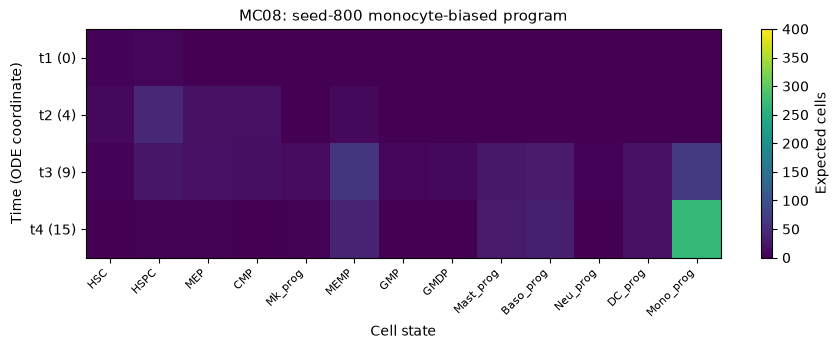

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Set Random Seed and Generate Parameters (Meta8 Bias)
# ---------------------------------------------------------

# Set seed for parameter generation
np.random.seed(800) # Changed seed for Meta8

# --- Stem & Early Progenitors ---
p_hsc = 0.2 + np.random.randn() * 0.02
d_hsc = 0.1 + np.random.randn() * 0.01
m_hsc = 0.02 + np.random.randn() * 0.002

p_hspc = 0.3 + np.random.randn() * 0.03
d_hspc = 0.1 + np.random.randn() * 0.01
m_hspc = 0.011 + np.random.randn() * 0.0011

# --- Erythroid / Megakaryocyte Branch ---
p_mep = 0.41 + np.random.randn() * 0.041
d_mep = 0.11 + np.random.randn() * 0.011
m_mep = 0.012 + np.random.randn() * 0.0012

p_cmp = 0.2 + np.random.randn() * 0.02
d_cmp = 0.09 + np.random.randn() * 0.009
m_cmp = 0.02 + np.random.randn() * 0.002

p_mk = 0.29 + np.random.randn() * 0.029
m_mk = 0.02 + np.random.randn() * 0.002

p_memp = 0.6 + np.random.randn() * 0.06
d_memp = 0.1 + np.random.randn() * 0.01
m_memp = 0.015 + np.random.randn() * 0.0015

# --- Granulocyte / Monocyte Branch ---
p_gmp = 0.5 + np.random.randn() * 0.05
d_gmp = 0.3 + np.random.randn() * 0.03
m_gmp = 0.018 + np.random.randn() * 0.0018

# MODIFICATION: Increased GMDP proliferation to feed Mono/DC
p_gmdp = 0.6 + np.random.randn() * 0.04 
d_gmdp = 0.3 + np.random.randn() * 0.03
m_gmdp = 0.071 + np.random.randn() * 0.0071

# --- Terminal Lineages ---
p_mast = 0.6 + np.random.randn() * 0.06
m_mast = 0.08 + np.random.randn() * 0.008

p_baso = 0.51 + np.random.randn() * 0.051
m_baso = 0.02 + np.random.randn() * 0.002

# MODIFICATION: Suppressed Neutrophils to emphasize Mono bias
p_neu = 0.1 + np.random.randn() * 0.03 
m_neu = 0.133 + np.random.randn() * 0.0133

p_dc = 0.6 + np.random.randn() * 0.06
m_dc = 0.11 + np.random.randn() * 0.011

# MODIFICATION: Drastic increase in Monocyte proliferation
p_mono = 0.85 + np.random.randn() * 0.0145 
m_mono = 0.012 + np.random.randn() * 0.0012

print("Generated parameters for Meta8 (Mono Bias):")
print(f"p_mono={p_mono:.4f} (High), p_neu={p_neu:.4f} (Low)")
print(f"p_gmdp={p_gmdp:.4f} (High)")

# ---------------------------------------------------------
# 2. Define ODE System with Generated Parameters
# ---------------------------------------------------------

def hematopoietic_model(t, y):
    dydt = np.zeros_like(y)
    x = y 

    # ODE Equations
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    return dydt

# ---------------------------------------------------------
# 3. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
t_plot = np.linspace(0, 20, 2001)

# Initial Conditions: HSC=1, HSPC=2, others=0
I0 = np.zeros(13)
I0[0] = 1.0  # HSC
I0[1] = 2.0  # HSPC

# ---------------------------------------------------------
# 4. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)

# Target sums for each timepoint: [10, 100, 300, 400]
target_sums = np.array([10, 100, 300, 400]).reshape(-1, 1)

# Normalize and Scale: (Model / Current_Sum) * Target_Sum
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------


# Record this program, verify its exact expected counts, and draw one profile heatmap.
program_number=8
program_id=f'MC{program_number:02d}'
program_clone_count=20
program_seed=800
program_rates={name:float(globals()[name]) for name in ['p_hsc', 'd_hsc', 'm_hsc', 'p_hspc', 'd_hspc', 'm_hspc', 'p_mep', 'd_mep', 'm_mep', 'p_cmp', 'd_cmp', 'm_cmp', 'p_mk', 'm_mk', 'p_memp', 'd_memp', 'm_memp', 'p_gmp', 'd_gmp', 'm_gmp', 'p_gmdp', 'd_gmdp', 'm_gmdp', 'p_mast', 'm_mast', 'p_baso', 'm_baso', 'p_neu', 'm_neu', 'p_dc', 'm_dc', 'p_mono', 'm_mono']}
rate_expressions={'p_hsc': '0.2 + np.random.randn() * 0.02', 'd_hsc': '0.1 + np.random.randn() * 0.01', 'm_hsc': '0.02 + np.random.randn() * 0.002', 'p_hspc': '0.3 + np.random.randn() * 0.03', 'd_hspc': '0.1 + np.random.randn() * 0.01', 'm_hspc': '0.011 + np.random.randn() * 0.0011', 'p_mep': '0.41 + np.random.randn() * 0.041', 'd_mep': '0.11 + np.random.randn() * 0.011', 'm_mep': '0.012 + np.random.randn() * 0.0012', 'p_cmp': '0.2 + np.random.randn() * 0.02', 'd_cmp': '0.09 + np.random.randn() * 0.009', 'm_cmp': '0.02 + np.random.randn() * 0.002', 'p_mk': '0.29 + np.random.randn() * 0.029', 'm_mk': '0.02 + np.random.randn() * 0.002', 'p_memp': '0.6 + np.random.randn() * 0.06', 'd_memp': '0.1 + np.random.randn() * 0.01', 'm_memp': '0.015 + np.random.randn() * 0.0015', 'p_gmp': '0.5 + np.random.randn() * 0.05', 'd_gmp': '0.3 + np.random.randn() * 0.03', 'm_gmp': '0.018 + np.random.randn() * 0.0018', 'p_gmdp': '0.6 + np.random.randn() * 0.04', 'd_gmdp': '0.3 + np.random.randn() * 0.03', 'm_gmdp': '0.071 + np.random.randn() * 0.0071', 'p_mast': '0.6 + np.random.randn() * 0.06', 'm_mast': '0.08 + np.random.randn() * 0.008', 'p_baso': '0.51 + np.random.randn() * 0.051', 'm_baso': '0.02 + np.random.randn() * 0.002', 'p_neu': '0.1 + np.random.randn() * 0.03', 'm_neu': '0.133 + np.random.randn() * 0.0133', 'p_dc': '0.6 + np.random.randn() * 0.06', 'm_dc': '0.11 + np.random.randn() * 0.011', 'p_mono': '0.85 + np.random.randn() * 0.0145', 'm_mono': '0.012 + np.random.randn() * 0.0012'}
ode_equations='def hematopoietic_model(t, y):\n    dydt = np.zeros_like(y)\n    x = y \n\n    # ODE Equations\n    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] \n    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]\n    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]\n    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]\n    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]\n    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]\n    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]\n    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]\n    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]\n    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]\n    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]\n    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]\n    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]\n\n    return dydt'
source_record={'program': 'MC08', 'historical_notebook': 'simulation_generate.ipynb', 'historical_notebook_sha256': 'a35588c48c547954c48c14d5def17da4b3ed1238a281cf78d20473e1c48a2cea', 'historical_cell_zero_based': 16, 'deterministic_prefix_sha256': '2b9e3012ddd5ae3bc0d0a8f5885396d0e077c70cb321b9b047009487a79af9c2', 'boundary': 'before # Calculate deviation', 'n_clones': 20, 'parameter_seed': 800}
assert sol_sample.success and sol_plot.success
profile=np.asarray(model_deterministic,dtype=np.float64).copy()
assert profile.shape==(4,13) and np.isfinite(profile).all() and (profile>=0).all()
assert np.array_equal(time_points,np.array([0,4,9,15]))
assert np.array_equal(profile,canonical_profiles[program_number-1]),program_id
assert program_clone_count==int(canonical_manifest.iloc[program_number-1]['n_clones'])
profiles.append(profile)
description=str(canonical_manifest.iloc[program_number-1]['description'])
program_record=dict(source_record,description=description,initial_conditions=I0.tolist(),
                    sampling_coordinates=time_points.tolist(),target_sums=target_sums.ravel().tolist(),
                    solver='RK45',solver_defaults=rk45_defaults,rate_values=program_rates,
                    rate_expressions=rate_expressions,ode_equations=ode_equations,
                    transformation='round sampled ODE values to nearest even, then rescale each timepoint to its target total')
program_records.append(program_record)
parameter_records.extend({'program':program_id,'parameter':name,'value':float(value),
                          'expression':rate_expressions[name],'parameter_seed':program_seed}
                         for name,value in program_rates.items())
equivalence_records.append({'program':program_id,'n_clones':program_clone_count,
                            'exact_profile_match':True,'maximum_absolute_difference':float(np.max(np.abs(profile-canonical_profiles[program_number-1])))})
display(pd.DataFrame(profile,index=TIME_LABELS,columns=STATES))

with mpl.rc_context({'svg.fonttype':'none','pdf.fonttype':42,'font.family':'DejaVu Sans'}):
    fig,ax=plt.subplots(figsize=(9,3.6))
    image=ax.imshow(profile,aspect='auto',cmap='viridis',vmin=0,
                    vmax=float(canonical_profiles.max()),interpolation='nearest')
    ax.set_xticks(np.arange(len(STATES)))
    ax.set_xticklabels(STATES,rotation=45,ha='right',fontsize=8)
    ax.set_yticks(np.arange(len(TIME_LABELS)))
    ax.set_yticklabels([f'{label} ({coordinate})' for label,coordinate in zip(TIME_LABELS,time_points)])
    ax.set_xlabel('Cell state')
    ax.set_ylabel('Time (ODE coordinate)')
    ax.set_title(f'{program_id}: {description}',fontsize=11)
    fig.colorbar(image,ax=ax,label='Expected cells')
    fig.tight_layout()
    stem=FIGURES/f'{program_id.lower()}_deterministic_profile'
    fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'),dpi=180,bbox_inches='tight')
    display(fig)
plt.close(fig)
figure_records.append({'program':program_id,'svg':str(stem.with_suffix('.svg').relative_to(BENCHMARK)),
                       'svg_sha256':sha(stem.with_suffix('.svg')),
                       'png':str(stem.with_suffix('.png').relative_to(BENCHMARK)),
                       'png_sha256':sha(stem.with_suffix('.png'))})


## Program 9

The complete deterministic calculation and its profile plot are in one cell. The result is checked against the corresponding registered program before export.

Generated parameters for Meta9 (Dying Out):
Standard parameters generated. Kill switch active > t=7.5.


,HSC,HSPC,MEP,CMP,Mk_prog,MEMP,GMP,GMDP,Mast_prog,Baso_prog,Neu_prog,DC_prog,Mono_prog
t1,3.333333,6.666667,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
t2,8.333333,41.666667,16.666667,16.666667,8.333333,8.333333,0.0,0.0,0.0,0.0,0.0,0.0,0.0
t3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
t4,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0


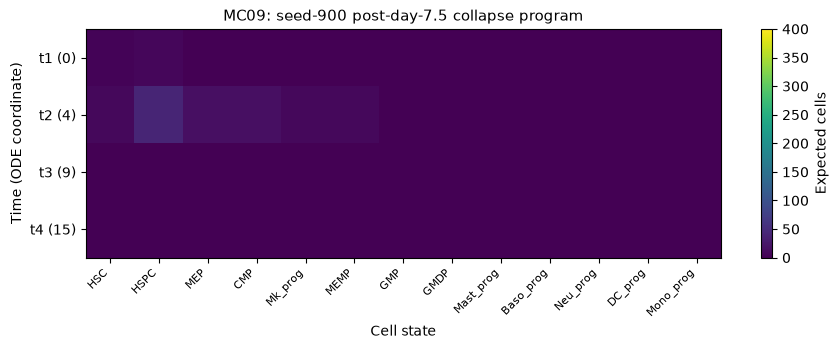

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Set Random Seed and Generate Parameters (Meta8 Bias kept)
# ---------------------------------------------------------

# Set seed for parameter generation
np.random.seed(900) 

# --- Stem & Early Progenitors ---
p_hsc = 0.2 + np.random.randn() * 0.02
d_hsc = 0.1 + np.random.randn() * 0.01
m_hsc = 0.02 + np.random.randn() * 0.002

p_hspc = 0.3 + np.random.randn() * 0.03
d_hspc = 0.1 + np.random.randn() * 0.01
m_hspc = 0.011 + np.random.randn() * 0.0011

# --- Erythroid / Megakaryocyte Branch ---
p_mep = 0.41 + np.random.randn() * 0.041
d_mep = 0.11 + np.random.randn() * 0.011
m_mep = 0.012 + np.random.randn() * 0.0012

p_cmp = 0.2 + np.random.randn() * 0.02
d_cmp = 0.09 + np.random.randn() * 0.009
m_cmp = 0.02 + np.random.randn() * 0.002

p_mk = 0.29 + np.random.randn() * 0.029
m_mk = 0.02 + np.random.randn() * 0.002

p_memp = 0.6 + np.random.randn() * 0.06
d_memp = 0.1 + np.random.randn() * 0.01
m_memp = 0.015 + np.random.randn() * 0.0015

# --- Granulocyte / Monocyte Branch ---
p_gmp = 0.5 + np.random.randn() * 0.05
d_gmp = 0.3 + np.random.randn() * 0.03
m_gmp = 0.018 + np.random.randn() * 0.0018

# (Kept Meta8 Bias) High GMDP
p_gmdp = 0.6 + np.random.randn() * 0.04 
d_gmdp = 0.3 + np.random.randn() * 0.03
m_gmdp = 0.071 + np.random.randn() * 0.0071

# --- Terminal Lineages ---
p_mast = 0.6 + np.random.randn() * 0.06
m_mast = 0.08 + np.random.randn() * 0.008

p_baso = 0.51 + np.random.randn() * 0.051
m_baso = 0.02 + np.random.randn() * 0.002

# (Kept Meta8 Bias) Suppressed Neu
p_neu = 0.1 + np.random.randn() * 0.03 
m_neu = 0.133 + np.random.randn() * 0.0133

p_dc = 0.6 + np.random.randn() * 0.06
m_dc = 0.11 + np.random.randn() * 0.011

# (Kept Meta8 Bias) High Mono
p_mono = 0.85 + np.random.randn() * 0.0145 
m_mono = 0.012 + np.random.randn() * 0.0012

print("Generated parameters for Meta9 (Dying Out):")
print("Standard parameters generated. Kill switch active > t=7.5.")

# ---------------------------------------------------------
# 2. Define ODE System with Kill Switch
# ---------------------------------------------------------

def hematopoietic_model(t, y):
    dydt = np.zeros_like(y)
    x = y 

    # META9 FEATURE: Catastrophic death event starts at t=7.5
    kill_rate = 0.0
    if t > 7.5:
        kill_rate = 5.0 # Massive death rate added to all cells

    # ODE Equations
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    # Apply kill rate to the entire system dynamics
    dydt -= kill_rate * x

    return dydt

# ---------------------------------------------------------
# 3. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
t_plot = np.linspace(0, 20, 2001)

# Initial Conditions: HSC=1, HSPC=2, others=0
I0 = np.zeros(13)
I0[0] = 1.0  # HSC
I0[1] = 2.0  # HSPC

# ---------------------------------------------------------
# 4. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)
model_deterministic[model_deterministic < 0] = 0 # Safety clip

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)
current_sums[current_sums == 0] = 1.0 # Avoid division by zero for the dead timepoints

# META9 FEATURE: Target sums collapse to near zero at day 9 and zero at day 15
# Previous: [10, 100, 300, 400]
target_sums = np.array([10, 100, 20, 0]).reshape(-1, 1)

# Normalize and Scale: (Model / Current_Sum) * Target_Sum
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------


# Record this program, verify its exact expected counts, and draw one profile heatmap.
program_number=9
program_id=f'MC{program_number:02d}'
program_clone_count=37
program_seed=900
program_rates={name:float(globals()[name]) for name in ['p_hsc', 'd_hsc', 'm_hsc', 'p_hspc', 'd_hspc', 'm_hspc', 'p_mep', 'd_mep', 'm_mep', 'p_cmp', 'd_cmp', 'm_cmp', 'p_mk', 'm_mk', 'p_memp', 'd_memp', 'm_memp', 'p_gmp', 'd_gmp', 'm_gmp', 'p_gmdp', 'd_gmdp', 'm_gmdp', 'p_mast', 'm_mast', 'p_baso', 'm_baso', 'p_neu', 'm_neu', 'p_dc', 'm_dc', 'p_mono', 'm_mono']}
rate_expressions={'p_hsc': '0.2 + np.random.randn() * 0.02', 'd_hsc': '0.1 + np.random.randn() * 0.01', 'm_hsc': '0.02 + np.random.randn() * 0.002', 'p_hspc': '0.3 + np.random.randn() * 0.03', 'd_hspc': '0.1 + np.random.randn() * 0.01', 'm_hspc': '0.011 + np.random.randn() * 0.0011', 'p_mep': '0.41 + np.random.randn() * 0.041', 'd_mep': '0.11 + np.random.randn() * 0.011', 'm_mep': '0.012 + np.random.randn() * 0.0012', 'p_cmp': '0.2 + np.random.randn() * 0.02', 'd_cmp': '0.09 + np.random.randn() * 0.009', 'm_cmp': '0.02 + np.random.randn() * 0.002', 'p_mk': '0.29 + np.random.randn() * 0.029', 'm_mk': '0.02 + np.random.randn() * 0.002', 'p_memp': '0.6 + np.random.randn() * 0.06', 'd_memp': '0.1 + np.random.randn() * 0.01', 'm_memp': '0.015 + np.random.randn() * 0.0015', 'p_gmp': '0.5 + np.random.randn() * 0.05', 'd_gmp': '0.3 + np.random.randn() * 0.03', 'm_gmp': '0.018 + np.random.randn() * 0.0018', 'p_gmdp': '0.6 + np.random.randn() * 0.04', 'd_gmdp': '0.3 + np.random.randn() * 0.03', 'm_gmdp': '0.071 + np.random.randn() * 0.0071', 'p_mast': '0.6 + np.random.randn() * 0.06', 'm_mast': '0.08 + np.random.randn() * 0.008', 'p_baso': '0.51 + np.random.randn() * 0.051', 'm_baso': '0.02 + np.random.randn() * 0.002', 'p_neu': '0.1 + np.random.randn() * 0.03', 'm_neu': '0.133 + np.random.randn() * 0.0133', 'p_dc': '0.6 + np.random.randn() * 0.06', 'm_dc': '0.11 + np.random.randn() * 0.011', 'p_mono': '0.85 + np.random.randn() * 0.0145', 'm_mono': '0.012 + np.random.randn() * 0.0012'}
ode_equations='def hematopoietic_model(t, y):\n    dydt = np.zeros_like(y)\n    x = y \n\n    # META9 FEATURE: Catastrophic death event starts at t=7.5\n    kill_rate = 0.0\n    if t > 7.5:\n        kill_rate = 5.0 # Massive death rate added to all cells\n\n    # ODE Equations\n    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] \n    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]\n    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]\n    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]\n    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]\n    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]\n    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]\n    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]\n    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]\n    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]\n    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]\n    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]\n    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]\n\n    # Apply kill rate to the entire system dynamics\n    dydt -= kill_rate * x\n\n    return dydt'
source_record={'program': 'MC09', 'historical_notebook': 'simulation_generate.ipynb', 'historical_notebook_sha256': 'a35588c48c547954c48c14d5def17da4b3ed1238a281cf78d20473e1c48a2cea', 'historical_cell_zero_based': 18, 'deterministic_prefix_sha256': 'bdc2149aeb9e82a4a7fa6ef3d2468dbaca76bec1466480dda3b2256b654f2113', 'boundary': 'before # Calculate deviation', 'n_clones': 37, 'parameter_seed': 900}
assert sol_sample.success and sol_plot.success
profile=np.asarray(model_deterministic,dtype=np.float64).copy()
assert profile.shape==(4,13) and np.isfinite(profile).all() and (profile>=0).all()
assert np.array_equal(time_points,np.array([0,4,9,15]))
assert np.array_equal(profile,canonical_profiles[program_number-1]),program_id
assert program_clone_count==int(canonical_manifest.iloc[program_number-1]['n_clones'])
profiles.append(profile)
description=str(canonical_manifest.iloc[program_number-1]['description'])
program_record=dict(source_record,description=description,initial_conditions=I0.tolist(),
                    sampling_coordinates=time_points.tolist(),target_sums=target_sums.ravel().tolist(),
                    solver='RK45',solver_defaults=rk45_defaults,rate_values=program_rates,
                    rate_expressions=rate_expressions,ode_equations=ode_equations,
                    transformation='round sampled ODE values to nearest even, then rescale each timepoint to its target total')
program_records.append(program_record)
parameter_records.extend({'program':program_id,'parameter':name,'value':float(value),
                          'expression':rate_expressions[name],'parameter_seed':program_seed}
                         for name,value in program_rates.items())
equivalence_records.append({'program':program_id,'n_clones':program_clone_count,
                            'exact_profile_match':True,'maximum_absolute_difference':float(np.max(np.abs(profile-canonical_profiles[program_number-1])))})
display(pd.DataFrame(profile,index=TIME_LABELS,columns=STATES))

with mpl.rc_context({'svg.fonttype':'none','pdf.fonttype':42,'font.family':'DejaVu Sans'}):
    fig,ax=plt.subplots(figsize=(9,3.6))
    image=ax.imshow(profile,aspect='auto',cmap='viridis',vmin=0,
                    vmax=float(canonical_profiles.max()),interpolation='nearest')
    ax.set_xticks(np.arange(len(STATES)))
    ax.set_xticklabels(STATES,rotation=45,ha='right',fontsize=8)
    ax.set_yticks(np.arange(len(TIME_LABELS)))
    ax.set_yticklabels([f'{label} ({coordinate})' for label,coordinate in zip(TIME_LABELS,time_points)])
    ax.set_xlabel('Cell state')
    ax.set_ylabel('Time (ODE coordinate)')
    ax.set_title(f'{program_id}: {description}',fontsize=11)
    fig.colorbar(image,ax=ax,label='Expected cells')
    fig.tight_layout()
    stem=FIGURES/f'{program_id.lower()}_deterministic_profile'
    fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'),dpi=180,bbox_inches='tight')
    display(fig)
plt.close(fig)
figure_records.append({'program':program_id,'svg':str(stem.with_suffix('.svg').relative_to(BENCHMARK)),
                       'svg_sha256':sha(stem.with_suffix('.svg')),
                       'png':str(stem.with_suffix('.png').relative_to(BENCHMARK)),
                       'png_sha256':sha(stem.with_suffix('.png'))})


## Program 10

The complete deterministic calculation and its profile plot are in one cell. The result is checked against the corresponding registered program before export.

Generated parameters for Meta10 (Slowed/Delayed):
p_hsc=0.0411 (approx 0.25x of original)
d_hsc=0.0234 (approx 0.25x of original)


,HSC,HSPC,MEP,CMP,Mk_prog,MEMP,GMP,GMDP,Mast_prog,Baso_prog,Neu_prog,DC_prog,Mono_prog
t1,3.333333,6.666667,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
t2,33.333333,66.666667,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
t3,50.000000,150.000000,50.000000,50.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
t4,44.444444,177.777778,88.888889,44.444444,0.0,44.444444,0.0,0.0,0.0,0.0,0.0,0.0,0.0


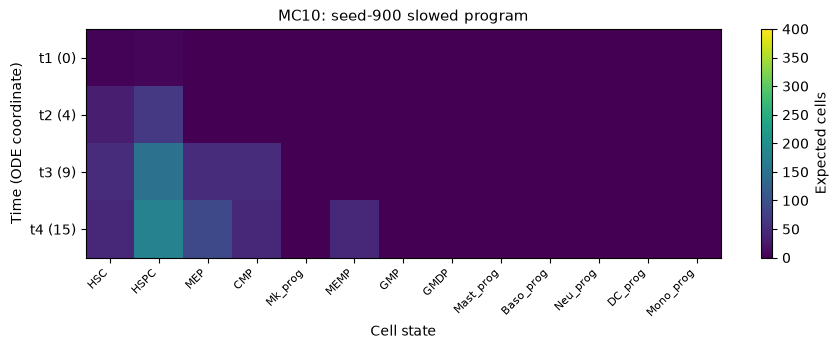

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Set Random Seed and Generate Parameters (Meta10 Slowed)
# ---------------------------------------------------------

# Set seed for parameter generation
np.random.seed(900) # New seed for Meta10

# Scaling factor to slow down dynamics (approx 4x slower)
# This effectively delays the "biological time" relative to "clock time"
slow_factor = 0.25

# Generate parameters with random noise, scaled by slow_factor
# Note: Migration/Death (m) is scaled less aggressively to avoid total washout
p_hsc = (0.2 + np.random.randn() * 0.02) * slow_factor
d_hsc = (0.1 + np.random.randn() * 0.01) * slow_factor
m_hsc = 0.02 + np.random.randn() * 0.002

p_hspc = (0.3 + np.random.randn() * 0.03) * slow_factor
d_hspc = (0.1 + np.random.randn() * 0.01) * slow_factor
m_hspc = 0.011 + np.random.randn() * 0.0011

p_mep = (0.41 + np.random.randn() * 0.041) * slow_factor
d_mep = (0.11 + np.random.randn() * 0.011) * slow_factor
m_mep = 0.012 + np.random.randn() * 0.0012

p_cmp = (0.2 + np.random.randn() * 0.02) * slow_factor
d_cmp = (0.09 + np.random.randn() * 0.009) * slow_factor
m_cmp = 0.02 + np.random.randn() * 0.002

p_mk = (0.29 + np.random.randn() * 0.029) * slow_factor
m_mk = 0.02 + np.random.randn() * 0.002

p_memp = (0.6 + np.random.randn() * 0.06) * slow_factor
d_memp = (0.1 + np.random.randn() * 0.01) * slow_factor
m_memp = 0.015 + np.random.randn() * 0.0015

p_gmp = (0.5 + np.random.randn() * 0.05) * slow_factor
d_gmp = (0.3 + np.random.randn() * 0.03) * slow_factor
m_gmp = 0.018 + np.random.randn() * 0.0018

p_gmdp = (0.4 + np.random.randn() * 0.04) * slow_factor
d_gmdp = (0.3 + np.random.randn() * 0.03) * slow_factor
m_gmdp = 0.071 + np.random.randn() * 0.0071

p_mast = (0.6 + np.random.randn() * 0.06) * slow_factor
m_mast = 0.08 + np.random.randn() * 0.008

p_baso = (0.51 + np.random.randn() * 0.051) * slow_factor
m_baso = 0.02 + np.random.randn() * 0.002

p_neu = (0.3 + np.random.randn() * 0.03) * slow_factor
m_neu = 0.133 + np.random.randn() * 0.0133

p_dc = (0.6 + np.random.randn() * 0.06) * slow_factor
m_dc = 0.11 + np.random.randn() * 0.011

p_mono = (0.145 + np.random.randn() * 0.0145) * slow_factor
m_mono = 0.012 + np.random.randn() * 0.0012

print("Generated parameters for Meta10 (Slowed/Delayed):")
print(f"p_hsc={p_hsc:.4f} (approx {slow_factor}x of original)")
print(f"d_hsc={d_hsc:.4f} (approx {slow_factor}x of original)")

# ---------------------------------------------------------
# 2. Define ODE System
# ---------------------------------------------------------

def hematopoietic_model(t, y):
    dydt = np.zeros_like(y)
    x = y 

    # ODE Equations (using globally generated parameters)
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    return dydt

# ---------------------------------------------------------
# 3. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
t_plot = np.linspace(0, 20, 2001)

# Initial Conditions: HSC=1, HSPC=2, others=0
I0 = np.zeros(13)
I0[0] = 1.0  # HSC
I0[1] = 2.0  # HSPC

# ---------------------------------------------------------
# 4. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)

# Target sums: Same as original [10, 100, 300, 400]
# Note: Because dynamics are slower, the model might struggle to reach high counts
# naturally, but this scaling forces the "observed" total count to match the original pattern.
# The *proportions* will be "delayed" (less mature cells at later timepoints).
target_sums = np.array([10, 100, 300, 400]).reshape(-1, 1)

# Normalize and Scale
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------


# Record this program, verify its exact expected counts, and draw one profile heatmap.
program_number=10
program_id=f'MC{program_number:02d}'
program_clone_count=53
program_seed=900
program_rates={name:float(globals()[name]) for name in ['p_hsc', 'd_hsc', 'm_hsc', 'p_hspc', 'd_hspc', 'm_hspc', 'p_mep', 'd_mep', 'm_mep', 'p_cmp', 'd_cmp', 'm_cmp', 'p_mk', 'm_mk', 'p_memp', 'd_memp', 'm_memp', 'p_gmp', 'd_gmp', 'm_gmp', 'p_gmdp', 'd_gmdp', 'm_gmdp', 'p_mast', 'm_mast', 'p_baso', 'm_baso', 'p_neu', 'm_neu', 'p_dc', 'm_dc', 'p_mono', 'm_mono']}
rate_expressions={'p_hsc': '(0.2 + np.random.randn() * 0.02) * slow_factor', 'd_hsc': '(0.1 + np.random.randn() * 0.01) * slow_factor', 'm_hsc': '0.02 + np.random.randn() * 0.002', 'p_hspc': '(0.3 + np.random.randn() * 0.03) * slow_factor', 'd_hspc': '(0.1 + np.random.randn() * 0.01) * slow_factor', 'm_hspc': '0.011 + np.random.randn() * 0.0011', 'p_mep': '(0.41 + np.random.randn() * 0.041) * slow_factor', 'd_mep': '(0.11 + np.random.randn() * 0.011) * slow_factor', 'm_mep': '0.012 + np.random.randn() * 0.0012', 'p_cmp': '(0.2 + np.random.randn() * 0.02) * slow_factor', 'd_cmp': '(0.09 + np.random.randn() * 0.009) * slow_factor', 'm_cmp': '0.02 + np.random.randn() * 0.002', 'p_mk': '(0.29 + np.random.randn() * 0.029) * slow_factor', 'm_mk': '0.02 + np.random.randn() * 0.002', 'p_memp': '(0.6 + np.random.randn() * 0.06) * slow_factor', 'd_memp': '(0.1 + np.random.randn() * 0.01) * slow_factor', 'm_memp': '0.015 + np.random.randn() * 0.0015', 'p_gmp': '(0.5 + np.random.randn() * 0.05) * slow_factor', 'd_gmp': '(0.3 + np.random.randn() * 0.03) * slow_factor', 'm_gmp': '0.018 + np.random.randn() * 0.0018', 'p_gmdp': '(0.4 + np.random.randn() * 0.04) * slow_factor', 'd_gmdp': '(0.3 + np.random.randn() * 0.03) * slow_factor', 'm_gmdp': '0.071 + np.random.randn() * 0.0071', 'p_mast': '(0.6 + np.random.randn() * 0.06) * slow_factor', 'm_mast': '0.08 + np.random.randn() * 0.008', 'p_baso': '(0.51 + np.random.randn() * 0.051) * slow_factor', 'm_baso': '0.02 + np.random.randn() * 0.002', 'p_neu': '(0.3 + np.random.randn() * 0.03) * slow_factor', 'm_neu': '0.133 + np.random.randn() * 0.0133', 'p_dc': '(0.6 + np.random.randn() * 0.06) * slow_factor', 'm_dc': '0.11 + np.random.randn() * 0.011', 'p_mono': '(0.145 + np.random.randn() * 0.0145) * slow_factor', 'm_mono': '0.012 + np.random.randn() * 0.0012'}
ode_equations='def hematopoietic_model(t, y):\n    dydt = np.zeros_like(y)\n    x = y \n\n    # ODE Equations (using globally generated parameters)\n    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] \n    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]\n    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]\n    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]\n    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]\n    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]\n    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]\n    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]\n    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]\n    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]\n    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]\n    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]\n    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]\n\n    return dydt'
source_record={'program': 'MC10', 'historical_notebook': 'simulation_generate.ipynb', 'historical_notebook_sha256': 'a35588c48c547954c48c14d5def17da4b3ed1238a281cf78d20473e1c48a2cea', 'historical_cell_zero_based': 20, 'deterministic_prefix_sha256': 'a9ffa65e7a9f6869899cddd0275c09b1c4d9eb8db656322827232b0b0fcd3e50', 'boundary': 'before # Calculate deviation', 'n_clones': 53, 'parameter_seed': 900}
assert sol_sample.success and sol_plot.success
profile=np.asarray(model_deterministic,dtype=np.float64).copy()
assert profile.shape==(4,13) and np.isfinite(profile).all() and (profile>=0).all()
assert np.array_equal(time_points,np.array([0,4,9,15]))
assert np.array_equal(profile,canonical_profiles[program_number-1]),program_id
assert program_clone_count==int(canonical_manifest.iloc[program_number-1]['n_clones'])
profiles.append(profile)
description=str(canonical_manifest.iloc[program_number-1]['description'])
program_record=dict(source_record,description=description,initial_conditions=I0.tolist(),
                    sampling_coordinates=time_points.tolist(),target_sums=target_sums.ravel().tolist(),
                    solver='RK45',solver_defaults=rk45_defaults,rate_values=program_rates,
                    rate_expressions=rate_expressions,ode_equations=ode_equations,
                    transformation='round sampled ODE values to nearest even, then rescale each timepoint to its target total')
program_records.append(program_record)
parameter_records.extend({'program':program_id,'parameter':name,'value':float(value),
                          'expression':rate_expressions[name],'parameter_seed':program_seed}
                         for name,value in program_rates.items())
equivalence_records.append({'program':program_id,'n_clones':program_clone_count,
                            'exact_profile_match':True,'maximum_absolute_difference':float(np.max(np.abs(profile-canonical_profiles[program_number-1])))})
display(pd.DataFrame(profile,index=TIME_LABELS,columns=STATES))

with mpl.rc_context({'svg.fonttype':'none','pdf.fonttype':42,'font.family':'DejaVu Sans'}):
    fig,ax=plt.subplots(figsize=(9,3.6))
    image=ax.imshow(profile,aspect='auto',cmap='viridis',vmin=0,
                    vmax=float(canonical_profiles.max()),interpolation='nearest')
    ax.set_xticks(np.arange(len(STATES)))
    ax.set_xticklabels(STATES,rotation=45,ha='right',fontsize=8)
    ax.set_yticks(np.arange(len(TIME_LABELS)))
    ax.set_yticklabels([f'{label} ({coordinate})' for label,coordinate in zip(TIME_LABELS,time_points)])
    ax.set_xlabel('Cell state')
    ax.set_ylabel('Time (ODE coordinate)')
    ax.set_title(f'{program_id}: {description}',fontsize=11)
    fig.colorbar(image,ax=ax,label='Expected cells')
    fig.tight_layout()
    stem=FIGURES/f'{program_id.lower()}_deterministic_profile'
    fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'),dpi=180,bbox_inches='tight')
    display(fig)
plt.close(fig)
figure_records.append({'program':program_id,'svg':str(stem.with_suffix('.svg').relative_to(BENCHMARK)),
                       'svg_sha256':sha(stem.with_suffix('.svg')),
                       'png':str(stem.with_suffix('.png').relative_to(BENCHMARK)),
                       'png_sha256':sha(stem.with_suffix('.png'))})


## Program 11

The complete deterministic calculation and its profile plot are in one cell. The result is checked against the corresponding registered program before export.

Generated parameters for Meta12 (Biological Stalling):
d_hsc=0.00087 (Extremely Low)
d_hspc=0.00105 (Extremely Low)


,HSC,HSPC,MEP,CMP,Mk_prog,MEMP,GMP,GMDP,Mast_prog,Baso_prog,Neu_prog,DC_prog,Mono_prog
t1,3.333333,6.666667,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
t2,25.000000,75.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
t3,52.173913,247.826087,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
t4,42.424242,354.208754,1.346801,2.020202,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


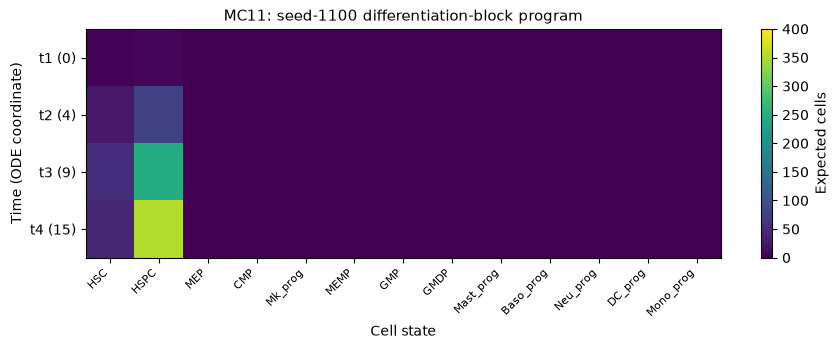

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Set Random Seed and Generate Parameters (Meta11)
# ---------------------------------------------------------

# Set seed
np.random.seed(1100)

# --- META12 MODIFICATION: EXTREME DIFFERENTIATION BLOCK ---
# We reduce 'd' (differentiation) rates to near zero.
# This causes cells to accumulate in HSC/HSPC and not flow downstream.

# HSC: Normal proliferation, but tiny differentiation
p_hsc = 0.3 + np.random.randn() * 0.02
d_hsc = 0.001 + np.random.randn() * 0.0001  # <--- The bottleneck
m_hsc = 0.02 + np.random.randn() * 0.002

# HSPC: Normal proliferation, tiny differentiation
p_hspc = 0.4 + np.random.randn() * 0.03
d_hspc = 0.001 + np.random.randn() * 0.0001 # <--- The bottleneck
m_hspc = 0.011 + np.random.randn() * 0.0011

# --- Downstream Progenitors (Parameters exist but get little input) ---
# We also slow these down to fit the "slow system" theme
p_mep = 0.2 + np.random.randn() * 0.02
d_mep = 0.01 + np.random.randn() * 0.001
m_mep = 0.012 + np.random.randn() * 0.0012

p_cmp = 0.2 + np.random.randn() * 0.02
d_cmp = 0.01 + np.random.randn() * 0.001
m_cmp = 0.02 + np.random.randn() * 0.002

p_mk = 0.2 + np.random.randn() * 0.02
m_mk = 0.02 + np.random.randn() * 0.002

p_memp = 0.2 + np.random.randn() * 0.02
d_memp = 0.01 + np.random.randn() * 0.001
m_memp = 0.015 + np.random.randn() * 0.0015

p_gmp = 0.2 + np.random.randn() * 0.02
d_gmp = 0.01 + np.random.randn() * 0.001
m_gmp = 0.018 + np.random.randn() * 0.0018

p_gmdp = 0.2 + np.random.randn() * 0.02
d_gmdp = 0.01 + np.random.randn() * 0.001
m_gmdp = 0.071 + np.random.randn() * 0.0071

p_mast = 0.2 + np.random.randn() * 0.02
m_mast = 0.08 + np.random.randn() * 0.008

p_baso = 0.2 + np.random.randn() * 0.02
m_baso = 0.02 + np.random.randn() * 0.002

p_neu = 0.2 + np.random.randn() * 0.02
m_neu = 0.133 + np.random.randn() * 0.0133

p_dc = 0.2 + np.random.randn() * 0.02
m_dc = 0.11 + np.random.randn() * 0.011

p_mono = 0.2 + np.random.randn() * 0.0145
m_mono = 0.012 + np.random.randn() * 0.0012

print("Generated parameters for Meta12 (Biological Stalling):")
print(f"d_hsc={d_hsc:.5f} (Extremely Low)")
print(f"d_hspc={d_hspc:.5f} (Extremely Low)")

# ---------------------------------------------------------
# 2. Define ODE System
# ---------------------------------------------------------

def hematopoietic_model(t, y):
    dydt = np.zeros_like(y)
    x = y 

    # ODE Equations
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    return dydt

# ---------------------------------------------------------
# 3. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
t_plot = np.linspace(0, 20, 2001)

# Initial Conditions: HSC=1, HSPC=2, others=0
I0 = np.zeros(13)
I0[0] = 1.0  # HSC
I0[1] = 2.0  # HSPC

# ---------------------------------------------------------
# 4. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)

# Target sums for each timepoint: [10, 100, 300, 400]
target_sums = np.array([10, 100, 300, 400]).reshape(-1, 1)

# Normalize and Scale: (Model / Current_Sum) * Target_Sum
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------


# Record this program, verify its exact expected counts, and draw one profile heatmap.
program_number=11
program_id=f'MC{program_number:02d}'
program_clone_count=26
program_seed=1100
program_rates={name:float(globals()[name]) for name in ['p_hsc', 'd_hsc', 'm_hsc', 'p_hspc', 'd_hspc', 'm_hspc', 'p_mep', 'd_mep', 'm_mep', 'p_cmp', 'd_cmp', 'm_cmp', 'p_mk', 'm_mk', 'p_memp', 'd_memp', 'm_memp', 'p_gmp', 'd_gmp', 'm_gmp', 'p_gmdp', 'd_gmdp', 'm_gmdp', 'p_mast', 'm_mast', 'p_baso', 'm_baso', 'p_neu', 'm_neu', 'p_dc', 'm_dc', 'p_mono', 'm_mono']}
rate_expressions={'p_hsc': '0.3 + np.random.randn() * 0.02', 'd_hsc': '0.001 + np.random.randn() * 0.0001', 'm_hsc': '0.02 + np.random.randn() * 0.002', 'p_hspc': '0.4 + np.random.randn() * 0.03', 'd_hspc': '0.001 + np.random.randn() * 0.0001', 'm_hspc': '0.011 + np.random.randn() * 0.0011', 'p_mep': '0.2 + np.random.randn() * 0.02', 'd_mep': '0.01 + np.random.randn() * 0.001', 'm_mep': '0.012 + np.random.randn() * 0.0012', 'p_cmp': '0.2 + np.random.randn() * 0.02', 'd_cmp': '0.01 + np.random.randn() * 0.001', 'm_cmp': '0.02 + np.random.randn() * 0.002', 'p_mk': '0.2 + np.random.randn() * 0.02', 'm_mk': '0.02 + np.random.randn() * 0.002', 'p_memp': '0.2 + np.random.randn() * 0.02', 'd_memp': '0.01 + np.random.randn() * 0.001', 'm_memp': '0.015 + np.random.randn() * 0.0015', 'p_gmp': '0.2 + np.random.randn() * 0.02', 'd_gmp': '0.01 + np.random.randn() * 0.001', 'm_gmp': '0.018 + np.random.randn() * 0.0018', 'p_gmdp': '0.2 + np.random.randn() * 0.02', 'd_gmdp': '0.01 + np.random.randn() * 0.001', 'm_gmdp': '0.071 + np.random.randn() * 0.0071', 'p_mast': '0.2 + np.random.randn() * 0.02', 'm_mast': '0.08 + np.random.randn() * 0.008', 'p_baso': '0.2 + np.random.randn() * 0.02', 'm_baso': '0.02 + np.random.randn() * 0.002', 'p_neu': '0.2 + np.random.randn() * 0.02', 'm_neu': '0.133 + np.random.randn() * 0.0133', 'p_dc': '0.2 + np.random.randn() * 0.02', 'm_dc': '0.11 + np.random.randn() * 0.011', 'p_mono': '0.2 + np.random.randn() * 0.0145', 'm_mono': '0.012 + np.random.randn() * 0.0012'}
ode_equations='def hematopoietic_model(t, y):\n    dydt = np.zeros_like(y)\n    x = y \n\n    # ODE Equations\n    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] \n    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]\n    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]\n    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]\n    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]\n    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]\n    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]\n    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]\n    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]\n    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]\n    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]\n    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]\n    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]\n\n    return dydt'
source_record={'program': 'MC11', 'historical_notebook': 'simulation_generate.ipynb', 'historical_notebook_sha256': 'a35588c48c547954c48c14d5def17da4b3ed1238a281cf78d20473e1c48a2cea', 'historical_cell_zero_based': 22, 'deterministic_prefix_sha256': 'fb579d683d1aa79896b0eb40e7118fdd036528a8862b4ae88a3a1f9d531964fd', 'boundary': 'before # Calculate deviation', 'n_clones': 26, 'parameter_seed': 1100}
assert sol_sample.success and sol_plot.success
profile=np.asarray(model_deterministic,dtype=np.float64).copy()
assert profile.shape==(4,13) and np.isfinite(profile).all() and (profile>=0).all()
assert np.array_equal(time_points,np.array([0,4,9,15]))
assert np.array_equal(profile,canonical_profiles[program_number-1]),program_id
assert program_clone_count==int(canonical_manifest.iloc[program_number-1]['n_clones'])
profiles.append(profile)
description=str(canonical_manifest.iloc[program_number-1]['description'])
program_record=dict(source_record,description=description,initial_conditions=I0.tolist(),
                    sampling_coordinates=time_points.tolist(),target_sums=target_sums.ravel().tolist(),
                    solver='RK45',solver_defaults=rk45_defaults,rate_values=program_rates,
                    rate_expressions=rate_expressions,ode_equations=ode_equations,
                    transformation='round sampled ODE values to nearest even, then rescale each timepoint to its target total')
program_records.append(program_record)
parameter_records.extend({'program':program_id,'parameter':name,'value':float(value),
                          'expression':rate_expressions[name],'parameter_seed':program_seed}
                         for name,value in program_rates.items())
equivalence_records.append({'program':program_id,'n_clones':program_clone_count,
                            'exact_profile_match':True,'maximum_absolute_difference':float(np.max(np.abs(profile-canonical_profiles[program_number-1])))})
display(pd.DataFrame(profile,index=TIME_LABELS,columns=STATES))

with mpl.rc_context({'svg.fonttype':'none','pdf.fonttype':42,'font.family':'DejaVu Sans'}):
    fig,ax=plt.subplots(figsize=(9,3.6))
    image=ax.imshow(profile,aspect='auto',cmap='viridis',vmin=0,
                    vmax=float(canonical_profiles.max()),interpolation='nearest')
    ax.set_xticks(np.arange(len(STATES)))
    ax.set_xticklabels(STATES,rotation=45,ha='right',fontsize=8)
    ax.set_yticks(np.arange(len(TIME_LABELS)))
    ax.set_yticklabels([f'{label} ({coordinate})' for label,coordinate in zip(TIME_LABELS,time_points)])
    ax.set_xlabel('Cell state')
    ax.set_ylabel('Time (ODE coordinate)')
    ax.set_title(f'{program_id}: {description}',fontsize=11)
    fig.colorbar(image,ax=ax,label='Expected cells')
    fig.tight_layout()
    stem=FIGURES/f'{program_id.lower()}_deterministic_profile'
    fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'),dpi=180,bbox_inches='tight')
    display(fig)
plt.close(fig)
figure_records.append({'program':program_id,'svg':str(stem.with_suffix('.svg').relative_to(BENCHMARK)),
                       'svg_sha256':sha(stem.with_suffix('.svg')),
                       'png':str(stem.with_suffix('.png').relative_to(BENCHMARK)),
                       'png_sha256':sha(stem.with_suffix('.png'))})


## Program 12

The complete deterministic calculation and its profile plot are in one cell. The result is checked against the corresponding registered program before export.

Generated parameters for Meta13 (HSC Only):
d_hsc=0.0001 (Trace), d_hspc=0.0 (Zero)


,HSC,HSPC,MEP,CMP,Mk_prog,MEMP,GMP,GMDP,Mast_prog,Baso_prog,Neu_prog,DC_prog,Mono_prog
t1,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
t2,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
t3,300.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
t4,400.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


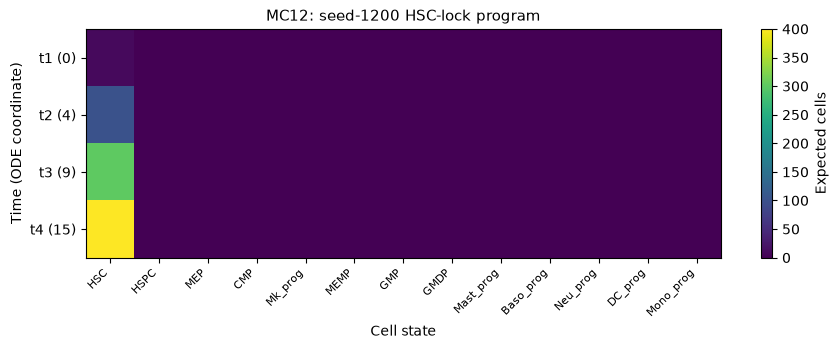

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import os

# ---------------------------------------------------------
# 1. Set Random Seed and Generate Parameters (Meta12)
# ---------------------------------------------------------

# Set seed
np.random.seed(1200)

# --- META13: THE "HSC LOCK" ---
# Proliferation exists, but differentiation is effectively zero.

p_hsc = 0.3 + np.random.randn() * 0.02
d_hsc = 0.0001  # <--- Virtually zero differentiation flux
m_hsc = 0.01 + np.random.randn() * 0.002

p_hspc = 0.3 + np.random.randn() * 0.03
d_hspc = 0.0    # <--- Absolute zero flow downstream
m_hspc = 0.011 + np.random.randn() * 0.0011

# --- Downstream (Irrelevant as no cells reach here) ---
p_mep = 0.41 + np.random.randn() * 0.041
d_mep = 0.11 + np.random.randn() * 0.011
m_mep = 0.012 + np.random.randn() * 0.0012

p_cmp = 0.2 + np.random.randn() * 0.02
d_cmp = 0.09 + np.random.randn() * 0.009
m_cmp = 0.02 + np.random.randn() * 0.002

p_mk = 0.29 + np.random.randn() * 0.029
m_mk = 0.02 + np.random.randn() * 0.002

p_memp = 0.6 + np.random.randn() * 0.06
d_memp = 0.1 + np.random.randn() * 0.01
m_memp = 0.015 + np.random.randn() * 0.0015

p_gmp = 0.5 + np.random.randn() * 0.05
d_gmp = 0.3 + np.random.randn() * 0.03
m_gmp = 0.018 + np.random.randn() * 0.0018

p_gmdp = 0.4 + np.random.randn() * 0.04
d_gmdp = 0.3 + np.random.randn() * 0.03
m_gmdp = 0.071 + np.random.randn() * 0.0071

p_mast = 0.6 + np.random.randn() * 0.06
m_mast = 0.08 + np.random.randn() * 0.008

p_baso = 0.51 + np.random.randn() * 0.051
m_baso = 0.02 + np.random.randn() * 0.002

p_neu = 0.3 + np.random.randn() * 0.03
m_neu = 0.133 + np.random.randn() * 0.0133

p_dc = 0.6 + np.random.randn() * 0.06
m_dc = 0.11 + np.random.randn() * 0.011

p_mono = 0.145 + np.random.randn() * 0.0145
m_mono = 0.012 + np.random.randn() * 0.0012

print("Generated parameters for Meta13 (HSC Only):")
print(f"d_hsc={d_hsc} (Trace), d_hspc={d_hspc} (Zero)")

# ---------------------------------------------------------
# 2. Define ODE System
# ---------------------------------------------------------

def hematopoietic_model(t, y):
    dydt = np.zeros_like(y)
    x = y 

    # ODE Equations
    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] 
    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]
    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]
    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]
    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]
    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]
    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]
    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]
    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]
    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]
    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]
    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]
    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]

    return dydt

# ---------------------------------------------------------
# 3. Simulation Setup
# ---------------------------------------------------------

cell_types = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk prog', 'MEMP', 
              'GMP', 'GMDP', 'Mast prog', 'Baso prog', 'Neu prog', 
              'DC prog', 'Mono prog']

time_points = np.array([0, 4, 9, 15])
t_plot = np.linspace(0, 20, 2001)

# Initial Conditions: HSC=1, HSPC=0 (Strict start)
I0 = np.zeros(13)
I0[0] = 1.0  # HSC
I0[1] = 0.0  # HSPC starts at 0 to ensure only d_hsc flux creates them

# ---------------------------------------------------------
# 4. Solve ODEs (Deterministic)
# ---------------------------------------------------------

sol_plot = solve_ivp(hematopoietic_model, [0, 20], I0, t_eval=t_plot, method='RK45')
sol_sample = solve_ivp(hematopoietic_model, [0, 15], I0, t_eval=time_points, method='RK45')

# Determine model values at sampling points (Time x Cell)
model_deterministic = np.round(sol_sample.y.T)

# --- SCALING SECTION ---
# Calculate current sum across cells for each timepoint
current_sums = model_deterministic.sum(axis=1, keepdims=True)

# Target sums for each timepoint: [10, 100, 300, 400]
target_sums = np.array([10, 100, 300, 400]).reshape(-1, 1)

# Normalize and Scale: (Model / Current_Sum) * Target_Sum
# Note: Since essentially only HSCs exist, HSC count will ~= Target Sum
model_deterministic = (model_deterministic / current_sums) * target_sums
# ----------------------


# Record this program, verify its exact expected counts, and draw one profile heatmap.
program_number=12
program_id=f'MC{program_number:02d}'
program_clone_count=30
program_seed=1200
program_rates={name:float(globals()[name]) for name in ['p_hsc', 'd_hsc', 'm_hsc', 'p_hspc', 'd_hspc', 'm_hspc', 'p_mep', 'd_mep', 'm_mep', 'p_cmp', 'd_cmp', 'm_cmp', 'p_mk', 'm_mk', 'p_memp', 'd_memp', 'm_memp', 'p_gmp', 'd_gmp', 'm_gmp', 'p_gmdp', 'd_gmdp', 'm_gmdp', 'p_mast', 'm_mast', 'p_baso', 'm_baso', 'p_neu', 'm_neu', 'p_dc', 'm_dc', 'p_mono', 'm_mono']}
rate_expressions={'p_hsc': '0.3 + np.random.randn() * 0.02', 'd_hsc': '0.0001', 'm_hsc': '0.01 + np.random.randn() * 0.002', 'p_hspc': '0.3 + np.random.randn() * 0.03', 'd_hspc': '0.0', 'm_hspc': '0.011 + np.random.randn() * 0.0011', 'p_mep': '0.41 + np.random.randn() * 0.041', 'd_mep': '0.11 + np.random.randn() * 0.011', 'm_mep': '0.012 + np.random.randn() * 0.0012', 'p_cmp': '0.2 + np.random.randn() * 0.02', 'd_cmp': '0.09 + np.random.randn() * 0.009', 'm_cmp': '0.02 + np.random.randn() * 0.002', 'p_mk': '0.29 + np.random.randn() * 0.029', 'm_mk': '0.02 + np.random.randn() * 0.002', 'p_memp': '0.6 + np.random.randn() * 0.06', 'd_memp': '0.1 + np.random.randn() * 0.01', 'm_memp': '0.015 + np.random.randn() * 0.0015', 'p_gmp': '0.5 + np.random.randn() * 0.05', 'd_gmp': '0.3 + np.random.randn() * 0.03', 'm_gmp': '0.018 + np.random.randn() * 0.0018', 'p_gmdp': '0.4 + np.random.randn() * 0.04', 'd_gmdp': '0.3 + np.random.randn() * 0.03', 'm_gmdp': '0.071 + np.random.randn() * 0.0071', 'p_mast': '0.6 + np.random.randn() * 0.06', 'm_mast': '0.08 + np.random.randn() * 0.008', 'p_baso': '0.51 + np.random.randn() * 0.051', 'm_baso': '0.02 + np.random.randn() * 0.002', 'p_neu': '0.3 + np.random.randn() * 0.03', 'm_neu': '0.133 + np.random.randn() * 0.0133', 'p_dc': '0.6 + np.random.randn() * 0.06', 'm_dc': '0.11 + np.random.randn() * 0.011', 'p_mono': '0.145 + np.random.randn() * 0.0145', 'm_mono': '0.012 + np.random.randn() * 0.0012'}
ode_equations='def hematopoietic_model(t, y):\n    dydt = np.zeros_like(y)\n    x = y \n\n    # ODE Equations\n    dydt[0] = (p_hsc - d_hsc - m_hsc) * x[0] \n    dydt[1] = (p_hspc - d_hspc - m_hspc) * x[1] + d_hsc * x[0]\n    dydt[2] = (p_mep - d_mep - m_mep) * x[2] + d_hspc * x[1]\n    dydt[3] = (p_cmp - d_cmp - m_cmp) * x[3] + d_hspc * x[1]\n    dydt[4] = (p_mk - m_mk) * x[4] + d_mep * x[2]\n    dydt[5] = (p_memp - d_memp - m_memp) * x[5] + d_mep * x[2] + d_cmp * x[3]\n    dydt[6] = (p_gmp - d_gmp - m_gmp) * x[6] + d_cmp * x[3]\n    dydt[7] = (p_gmdp - d_gmdp - m_gmdp) * x[7] + d_cmp * x[3]\n    dydt[8] = (p_mast - m_mast) * x[8] + d_memp * x[5]\n    dydt[9] = (p_baso - m_baso) * x[9] + d_memp * x[5]\n    dydt[10] = (p_neu - m_neu) * x[10] + d_gmp * x[6]\n    dydt[11] = (p_dc - m_dc) * x[11] + d_gmdp * x[7]\n    dydt[12] = (p_mono - m_mono) * x[12] + d_gmdp * x[7]\n\n    return dydt'
source_record={'program': 'MC12', 'historical_notebook': 'simulation_generate.ipynb', 'historical_notebook_sha256': 'a35588c48c547954c48c14d5def17da4b3ed1238a281cf78d20473e1c48a2cea', 'historical_cell_zero_based': 24, 'deterministic_prefix_sha256': '11b960612cef005a42bfa90fee5f8faa38dbeae8e902ff0fba88dd0a5d876d78', 'boundary': 'before # Calculate deviation', 'n_clones': 30, 'parameter_seed': 1200}
assert sol_sample.success and sol_plot.success
profile=np.asarray(model_deterministic,dtype=np.float64).copy()
assert profile.shape==(4,13) and np.isfinite(profile).all() and (profile>=0).all()
assert np.array_equal(time_points,np.array([0,4,9,15]))
assert np.array_equal(profile,canonical_profiles[program_number-1]),program_id
assert program_clone_count==int(canonical_manifest.iloc[program_number-1]['n_clones'])
profiles.append(profile)
description=str(canonical_manifest.iloc[program_number-1]['description'])
program_record=dict(source_record,description=description,initial_conditions=I0.tolist(),
                    sampling_coordinates=time_points.tolist(),target_sums=target_sums.ravel().tolist(),
                    solver='RK45',solver_defaults=rk45_defaults,rate_values=program_rates,
                    rate_expressions=rate_expressions,ode_equations=ode_equations,
                    transformation='round sampled ODE values to nearest even, then rescale each timepoint to its target total')
program_records.append(program_record)
parameter_records.extend({'program':program_id,'parameter':name,'value':float(value),
                          'expression':rate_expressions[name],'parameter_seed':program_seed}
                         for name,value in program_rates.items())
equivalence_records.append({'program':program_id,'n_clones':program_clone_count,
                            'exact_profile_match':True,'maximum_absolute_difference':float(np.max(np.abs(profile-canonical_profiles[program_number-1])))})
display(pd.DataFrame(profile,index=TIME_LABELS,columns=STATES))

with mpl.rc_context({'svg.fonttype':'none','pdf.fonttype':42,'font.family':'DejaVu Sans'}):
    fig,ax=plt.subplots(figsize=(9,3.6))
    image=ax.imshow(profile,aspect='auto',cmap='viridis',vmin=0,
                    vmax=float(canonical_profiles.max()),interpolation='nearest')
    ax.set_xticks(np.arange(len(STATES)))
    ax.set_xticklabels(STATES,rotation=45,ha='right',fontsize=8)
    ax.set_yticks(np.arange(len(TIME_LABELS)))
    ax.set_yticklabels([f'{label} ({coordinate})' for label,coordinate in zip(TIME_LABELS,time_points)])
    ax.set_xlabel('Cell state')
    ax.set_ylabel('Time (ODE coordinate)')
    ax.set_title(f'{program_id}: {description}',fontsize=11)
    fig.colorbar(image,ax=ax,label='Expected cells')
    fig.tight_layout()
    stem=FIGURES/f'{program_id.lower()}_deterministic_profile'
    fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight')
    fig.savefig(stem.with_suffix('.png'),dpi=180,bbox_inches='tight')
    display(fig)
plt.close(fig)
figure_records.append({'program':program_id,'svg':str(stem.with_suffix('.svg').relative_to(BENCHMARK)),
                       'svg_sha256':sha(stem.with_suffix('.svg')),
                       'png':str(stem.with_suffix('.png').relative_to(BENCHMARK)),
                       'png_sha256':sha(stem.with_suffix('.png'))})


## Export and verify the complete reference

The output CSV uses the canonical numeric formatting. Its checksum verifies the entire regenerated profile matrix. Clone counts are obtained from the source program definitions and checked against the manifest. The rounded clean tensor is included for the fixed-start noise workflow; the reference expected counts remain unrounded after their target-total scaling.

In [14]:
generated=np.stack(profiles)
assert generated.shape==(12,4,13)
profile_path=OUT/'deterministic_profiles.csv'
np.savetxt(profile_path,generated.reshape(12,52),delimiter=',',fmt='%.17g')
assert sha(profile_path)==expected_profile_sha
clone_counts=np.array([row['n_clones'] for row in program_records],dtype=np.int64)
assert np.array_equal(clone_counts,canonical_manifest['n_clones'].to_numpy())
manifest=canonical_manifest.copy()
manifest['n_clones']=clone_counts
manifest_path=OUT/'program_manifest.csv'
# Retain the canonical manifest's trailing blank line as well as its values.
manifest_path.write_text(manifest.to_csv(index=False)+'\n')
assert sha(manifest_path)==expected_manifest_sha
clean_means=np.repeat(generated,clone_counts,axis=0)
clean_counts=np.rint(clean_means).astype(np.int64)
assert clean_counts.shape==(int(clone_counts.sum()),4,13)
assert np.array_equal(clean_counts[:,0,:],np.rint(clean_means[:,0,:]).astype(np.int64))
np.savez_compressed(OUT/'clean_count_tensor.npz',counts=clean_counts,
                    clone_id=np.array([f'clone_{index:04d}' for index in range(len(clean_counts))]),
                    program=np.repeat(manifest['truth_metaclone'].to_numpy(dtype=str),clone_counts),
                    time=np.array([0,4,9,15]),state=np.asarray(STATES))
(OUT/'program_parameters.json').write_text(json.dumps(program_records,indent=2)+'\n')
pd.DataFrame(parameter_records).to_csv(OUT/'rate_parameters.csv',index=False)
conditions=[{key:row[key] for key in ['program','n_clones','parameter_seed','description','initial_conditions','sampling_coordinates','target_sums','solver']} for row in program_records]
pd.DataFrame(conditions).to_csv(OUT/'program_conditions.csv',index=False)
equivalence=pd.DataFrame(equivalence_records)
equivalence.to_csv(OUT/'reference_equivalence.csv',index=False)
assert sha(REFERENCE/'deterministic_profiles.csv')==expected_profile_sha
assert sha(REFERENCE/'program_manifest.csv')==expected_manifest_sha
receipt={'status':'passed','environment':environment,'programs':len(program_records),
         'shape':list(generated.shape),'clone_count':int(clone_counts.sum()),
         'exact_reference_agreement':True,'maximum_absolute_difference':float(np.max(np.abs(generated-canonical_profiles))),
         'profile_sha256':sha(profile_path),'manifest_sha256':sha(manifest_path),
         'parameter_rows':len(parameter_records),'figures':figure_records,
         'reference_inputs_unchanged':True,'historical_noise_suffix_executed':False,
         'noise_contract':'The separate corrected noise generator perturbs t2-t4 only; the complete rounded t1 vector remains fixed.'}
(OUT/'generation_validation.json').write_text(json.dumps(receipt,indent=2)+'\n')
display(equivalence)
display({key:receipt[key] for key in ['status','programs','shape','clone_count','exact_reference_agreement','maximum_absolute_difference','profile_sha256','manifest_sha256','parameter_rows','reference_inputs_unchanged']})


,program,n_clones,exact_profile_match,maximum_absolute_difference
0,MC01,15,True,0.0
1,MC02,30,True,0.0
2,MC03,50,True,0.0
3,MC04,40,True,0.0
4,MC05,72,True,0.0
5,MC06,56,True,0.0
6,MC07,88,True,0.0
7,MC08,20,True,0.0
8,MC09,37,True,0.0
9,MC10,53,True,0.0


{'status': 'passed',
 'programs': 12,
 'shape': [12, 4, 13],
 'clone_count': 517,
 'exact_reference_agreement': True,
 'maximum_absolute_difference': 0.0,
 'profile_sha256': 'e4275d94c1513026dc684bcca44703135bba4af4694ec55cd714d3c0fa21bf6f',
 'manifest_sha256': 'ba890ce14f052113d203904aa158cab79c36794c4edaf638ee0afd5b85063d11',
 'parameter_rows': 396,
 'reference_inputs_unchanged': True}